In [128]:
import pandas as pd
import numpy as np

pd.set_option("display.max_columns", None)
pd.set_option("display.max_colwidth", 100)

In [129]:
DATA_PATH = "../data/raw/tweets-engagement-metrics.csv"

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully.")
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

Dataset loaded successfully.
Rows: 102062
Columns: 20


In [130]:
df.head()

,Unnamed: 0,UserID,Gender,LocationID,City,State,StateCode,Country,TweetID,Hour,Day,Weekday,IsReshare,Reach,RetweetCount,Likes,Klout,Sentiment,Lang,text
0,0,tw-1267804344,Unknown,1.0,Elbasan,Elbasan,AL,Albania,tw-698155297102295041,7,12,Friday,True,339.0,127.0,0.0,44.0,0.0,en,"""RT @AdrianRusso82: Our Innovation Lab is officially open! Click below to learn more! https://ww..."
1,1,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-685159757209059329,11,7,Thursday,False,87.0,0.0,0.0,22.0,0.0,en,Now Open AWS Asia Pacific (Seoul) Region via /r/sysadmin https://www.reddit.com/r/sysadmin/comm...
2,2,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-686907710311378944,6,12,Tuesday,False,87.0,0.0,0.0,22.0,0.0,en,A Beginner's Guide to Scaling to 11 Million+ Users on Amazon's AWS via /r/sysadmin https://www.r...
3,3,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-686968158050201600,10,12,Tuesday,False,87.0,0.0,0.0,22.0,0.0,en,Bridging AWS and Azure environments via VPN via /r/sysadmin https://www.reddit.com/r/sysadmin/co...
4,4,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-690210449674092545,9,21,Thursday,False,85.0,0.0,0.0,21.0,0.0,en,ELK on AWS ElasticSearch Service + ElasticBeanstalk + Laravel via /r/sysadmin https://www.reddit...


In [131]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 102062 entries, 0 to 102061
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0    102062 non-null  int64  
 1   UserID        102062 non-null  str    
 2   Gender        102062 non-null  str    
 3   LocationID    102062 non-null  float64
 4   City          99783 non-null   str    
 5   State         100165 non-null  str    
 6   StateCode     100336 non-null  str    
 7   Country       102062 non-null  str    
 8   TweetID       102062 non-null  str    
 9   Hour          102062 non-null  int64  
 10  Day           102062 non-null  int64  
 11  Weekday       102062 non-null  str    
 12  IsReshare     102062 non-null  bool   
 13  Reach         102062 non-null  float64
 14  RetweetCount  102062 non-null  float64
 15  Likes         102062 non-null  float64
 16  Klout         102062 non-null  float64
 17  Sentiment     102062 non-null  float64
 18  Lang          1

In [132]:
print(df.columns.tolist())

['Unnamed: 0', 'UserID', 'Gender', 'LocationID', 'City', 'State', 'StateCode', 'Country', 'TweetID', 'Hour', 'Day', 'Weekday', 'IsReshare', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'Lang', 'text']


In [133]:
df.isnull().sum()

Unnamed: 0         0
UserID             0
Gender             0
LocationID         0
City            2279
State           1897
StateCode       1726
Country            0
TweetID            0
Hour               0
Day                0
Weekday            0
IsReshare          0
Reach              0
RetweetCount       0
Likes              0
Klout              0
Sentiment          0
Lang               0
text               0
dtype: int64

In [134]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 0


In [135]:
df.describe(include="all")  

,Unnamed: 0,UserID,Gender,LocationID,City,State,StateCode,Country,TweetID,Hour,Day,Weekday,IsReshare,Reach,RetweetCount,Likes,Klout,Sentiment,Lang,text
count,102062.000000,102062,102062,102062.000000,99783,100165,100336,102062,102062,102062.000000,102062.000000,102062,102062,1.020620e+05,102062.000000,102062.000000,102062.000000,102062.000000,102062,102062
unique,NaN,33212,4,NaN,3801,1008,357,151,99999,NaN,NaN,7,2,NaN,NaN,NaN,NaN,NaN,36,70267
top,NaN,tw-66780587,Male,NaN,Seattle,California,US-CA,United States,tw-710156266329546752,NaN,NaN,Tuesday,False,NaN,NaN,NaN,NaN,NaN,en,Zombiler uyandnda Amazon Web Services hazr olacak http://woisio.com/en/ife-and-love/56c11506e4b0...
freq,NaN,845,52603,NaN,7298,11734,11734,51457,3,NaN,NaN,18826,65852,NaN,NaN,NaN,NaN,NaN,93564,484
mean,51030.500000,NaN,NaN,2836.207687,NaN,NaN,NaN,NaN,NaN,11.416149,15.898709,NaN,NaN,8.426389e+03,7.986449,0.149684,40.409986,0.380754,NaN,NaN
std,29462.905924,NaN,NaN,1330.294460,NaN,NaN,NaN,NaN,NaN,6.062294,8.401409,NaN,NaN,8.777762e+04,96.914644,2.557491,13.652028,1.046501,NaN,NaN
min,0.000000,NaN,NaN,1.000000,NaN,NaN,NaN,NaN,NaN,0.000000,1.000000,NaN,NaN,0.000000e+00,0.000000,0.000000,0.000000,-6.000000,NaN,NaN
25%,25515.250000,NaN,NaN,1601.000000,NaN,NaN,NaN,NaN,NaN,7.000000,9.000000,NaN,NaN,1.520000e+02,0.000000,0.000000,32.000000,0.000000,NaN,NaN
50%,51030.500000,NaN,NaN,3738.000000,NaN,NaN,NaN,NaN,NaN,11.000000,16.000000,NaN,NaN,4.540000e+02,0.000000,0.000000,43.000000,0.000000,NaN,NaN
75%,76545.750000,NaN,NaN,3774.000000,NaN,NaN,NaN,NaN,NaN,16.000000,23.000000,NaN,NaN,1.519000e+03,3.000000,0.000000,49.000000,0.600000,NaN,NaN


In [136]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [137]:
from nltk.corpus import stopwords
import re

In [138]:
import nltk

nltk.download('stopwords')
nltk.download('punkt')

[nltk_data] Downloading package stopwords to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Package stopwords is already up-to-date!
[nltk_data] Downloading package punkt to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!


True

In [139]:
stop_words = set(stopwords.words("english"))

print("Number of English stopwords:", len(stop_words))

Number of English stopwords: 198


In [140]:
def clean_text(text):
    text = str(text)

    # Remove URLs
    text = re.sub(r"http\S+|www\S+|https\S+", "", text)

    # Remove mentions
    text = re.sub(r"@\w+", "", text)

    # Remove hashtags
    text = re.sub(r"#\w+", "", text)

    # Remove special characters and numbers
    text = re.sub(r"[^A-Za-z\s]", "", text)

    # Convert to lowercase
    text = text.lower()

    # Remove stopwords
    words = text.split()
    words = [word for word in words if word not in stop_words]

    return " ".join(words)

In [141]:
sample_text = df["text"].iloc[0]

print("Original:")
print(sample_text)

print("\nCleaned:")
print(clean_text(sample_text))

Original:
"RT @AdrianRusso82: Our Innovation Lab is officially open! Click below to learn more! https://www.linkedin.com/pulse/new-innovation-lab-open-business-adrian-russo-msis-mcp?utm_source&utm_medium&utm_campaign #Tech #JavaScript #AWS http"

Cleaned:
rt innovation lab officially open click learn


In [142]:
df["cleaned_text"] = df["text"].apply(clean_text)

print("Text cleaning completed.")
print("Rows processed:", len(df))

Text cleaning completed.
Rows processed: 102062


In [143]:
empty_cleaned = (df["cleaned_text"].str.strip() == "").sum()

print("Empty cleaned tweets:", empty_cleaned)

Empty cleaned tweets: 270


In [144]:
print("Total tweets:", len(df))
print("Non-empty cleaned tweets:", len(df) - empty_cleaned)

Total tweets: 102062
Non-empty cleaned tweets: 101792


In [145]:
from vaderSentiment.vaderSentiment import SentimentIntensityAnalyzer

analyzer = SentimentIntensityAnalyzer()

print("VADER sentiment analyzer initialized successfully.")

VADER sentiment analyzer initialized successfully.


In [146]:
sample_cleaned = df["cleaned_text"].iloc[0]

sentiment_scores = analyzer.polarity_scores(sample_cleaned)

print("Cleaned tweet:")
print(sample_cleaned)

print("\nVADER scores:")
print(sentiment_scores)

Cleaned tweet:
rt innovation lab officially open click learn

VADER scores:
{'neg': 0.0, 'neu': 0.698, 'pos': 0.302, 'compound': 0.3818}


In [147]:
df["vader_scores"] = df["cleaned_text"].apply(analyzer.polarity_scores)

print("VADER sentiment scoring completed.")
print("Rows processed:", len(df))

VADER sentiment scoring completed.
Rows processed: 102062


In [148]:
df[["cleaned_text", "vader_scores"]].head()

,cleaned_text,vader_scores
0,rt innovation lab officially open click learn,"{'neg': 0.0, 'neu': 0.698, 'pos': 0.302, 'compound': 0.3818}"
1,open aws asia pacific seoul region via rsysadmin,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}"
2,beginners guide scaling million users amazons aws via rsysadmin,"{'neg': 0.121, 'neu': 0.879, 'pos': 0.0, 'compound': -0.0258}"
3,bridging aws azure environments via vpn via rsysadmin,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}"
4,elk aws elasticsearch service elasticbeanstalk laravel via rsysadmin,"{'neg': 0.0, 'neu': 1.0, 'pos': 0.0, 'compound': 0.0}"


In [149]:
df["compound_score"] = df["vader_scores"].apply(lambda x: x["compound"])

print("Compound scores extracted successfully.")
print(df["compound_score"].head())

Compound scores extracted successfully.
0    0.3818
1    0.0000
2   -0.0258
3    0.0000
4    0.0000
Name: compound_score, dtype: float64


In [150]:
def classify_sentiment(score):
    if score >= 0.05:
        return "Positive"
    elif score <= -0.05:
        return "Negative"
    else:
        return "Neutral"


df["sentiment_label"] = df["compound_score"].apply(classify_sentiment)

print("Sentiment classification completed.")

Sentiment classification completed.


In [151]:
print(df["sentiment_label"].value_counts())

sentiment_label
Positive    48759
Neutral     45957
Negative     7346
Name: count, dtype: int64


In [152]:
print("Sentiment Distribution:")
print(df["sentiment_label"].value_counts())

Sentiment Distribution:
sentiment_label
Positive    48759
Neutral     45957
Negative     7346
Name: count, dtype: int64


In [153]:
import matplotlib.pyplot as plt
import seaborn as sns

KeyboardInterrupt: 

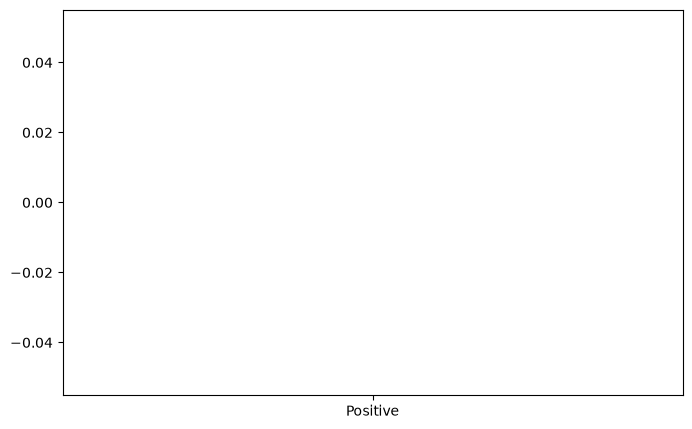

In [154]:
sentiment_counts = df["sentiment_label"].value_counts()

plt.figure(figsize=(8, 5))

sns.barplot(
    x=sentiment_counts.index,
    y=sentiment_counts.values
)

plt.title("Sentiment Distribution")
plt.xlabel("Sentiment")
plt.ylabel("Number of Tweets")

plt.savefig(
    "../outputs/plots/sentiment_distribution.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
sentiment_percentage = (
    df["sentiment_label"]
    .value_counts(normalize=True)
    .mul(100)
    .round(2)
)

print("Sentiment Percentage:")
print(sentiment_percentage)

Sentiment Percentage:
sentiment_label
Positive    47.77
Neutral     45.03
Negative     7.20
Name: proportion, dtype: float64


In [ ]:
from wordcloud import WordCloud

In [ ]:
positive_text = " ".join(
    df.loc[df["sentiment_label"] == "Positive", "cleaned_text"]
)

negative_text = " ".join(
    df.loc[df["sentiment_label"] == "Negative", "cleaned_text"]
)

neutral_text = " ".join(
    df.loc[df["sentiment_label"] == "Neutral", "cleaned_text"]
)

print("Positive text length:", len(positive_text))
print("Negative text length:", len(negative_text))
print("Neutral text length:", len(neutral_text))

Positive text length: 2968913
Negative text length: 451889
Neutral text length: 2307922


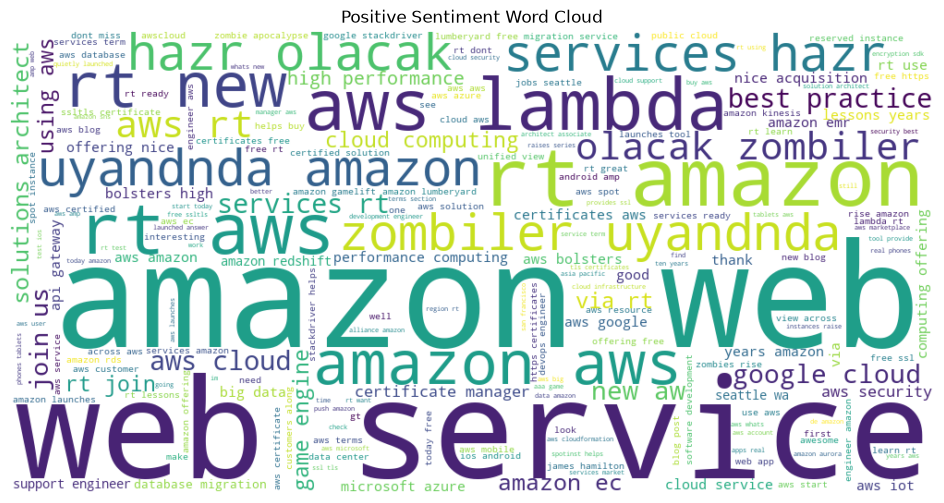

In [ ]:
positive_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(positive_text)

plt.figure(figsize=(12, 6))
plt.imshow(positive_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Positive Sentiment Word Cloud")
plt.show()

positive_wordcloud.to_file(
    "../outputs/wordclouds/positive_wordcloud.png"
)

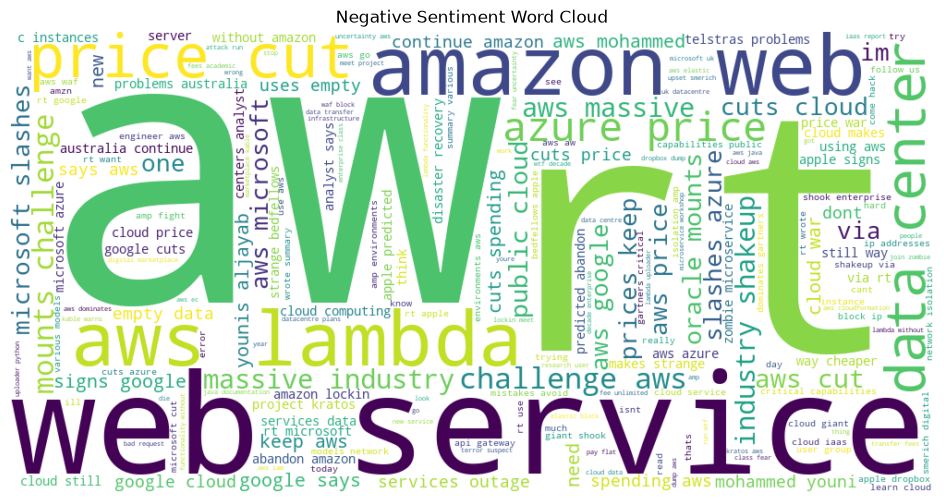

In [ ]:
negative_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(negative_text)

plt.figure(figsize=(12, 6))
plt.imshow(negative_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Negative Sentiment Word Cloud")
plt.show()

negative_wordcloud.to_file(
    "../outputs/wordclouds/negative_wordcloud.png"
)

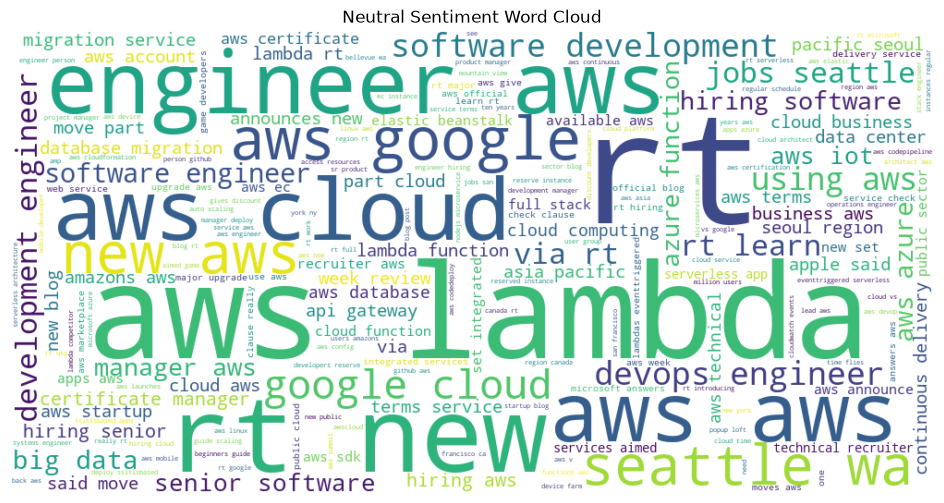

In [ ]:
neutral_wordcloud = WordCloud(
    width=1000,
    height=500,
    background_color="white"
).generate(neutral_text)

plt.figure(figsize=(12, 6))
plt.imshow(neutral_wordcloud, interpolation="bilinear")
plt.axis("off")
plt.title("Neutral Sentiment Word Cloud")
plt.show()

neutral_wordcloud.to_file(
    "../outputs/wordclouds/neutral_wordcloud.png"
)


In [ ]:
hour_counts = df["Hour"].value_counts().sort_index()

print("Tweets by Hour:")
print(hour_counts)

Tweets by Hour:
Hour
0     2839
1     3124
2     3207
3     2993
4     3182
5     3570
6     4373
7     5000
8     5415
9     6051
10    6255
11    6274
12    5912
13    5432
14    5315
15    5202
16    4772
17    4434
18    3700
19    3492
20    3113
21    3023
22    2774
23    2610
Name: count, dtype: int64


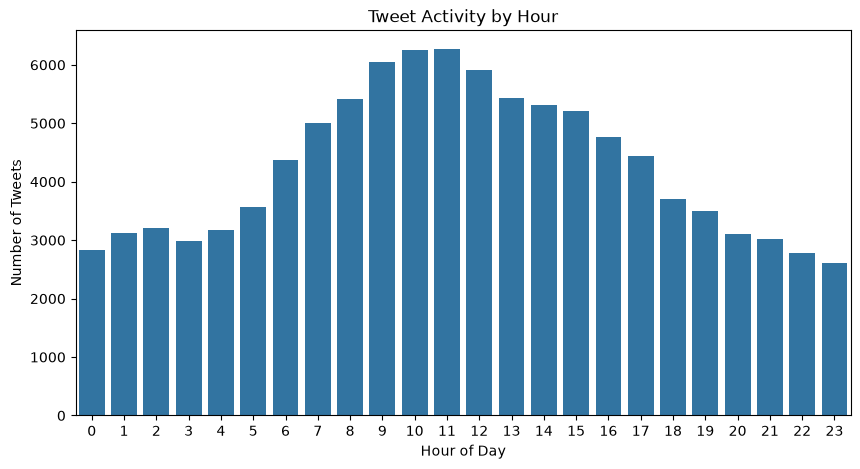

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=hour_counts.index,
    y=hour_counts.values
)

plt.title("Tweet Activity by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Number of Tweets")

plt.savefig(
    "../outputs/plots/tweet_activity_by_hour.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
most_active_hour = hour_counts.idxmax()
most_active_hour_count = hour_counts.max()

print("Most active hour:", most_active_hour)
print("Number of tweets:", most_active_hour_count)

Most active hour: 11
Number of tweets: 6274


In [ ]:
weekday_counts = df["Weekday"].value_counts()

print("Tweets by Weekday:")
print(weekday_counts)

Tweets by Weekday:
Weekday
Tuesday      18826
Thursday     18819
Wednesday    18578
Monday       15746
Friday       15273
Saturday      7636
Sunday        7184
Name: count, dtype: int64


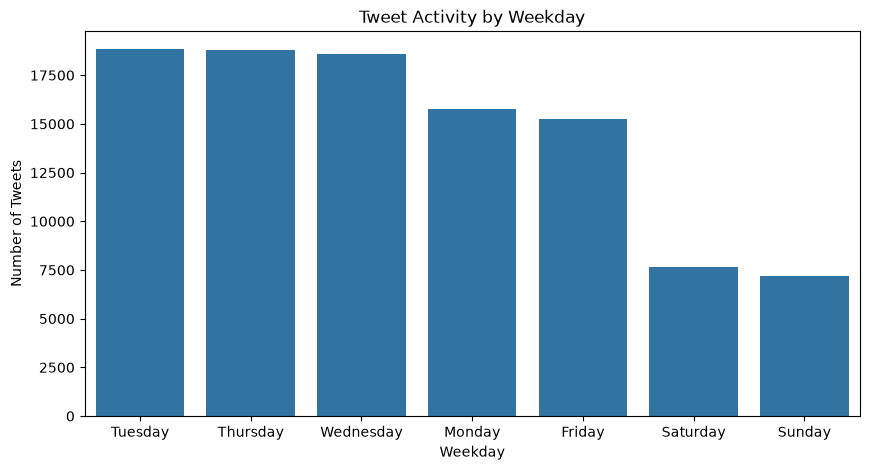

In [ ]:
plt.figure(figsize=(10, 5))

sns.barplot(
    x=weekday_counts.index,
    y=weekday_counts.values
)

plt.title("Tweet Activity by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Number of Tweets")

plt.savefig(
    "../outputs/plots/tweet_activity_by_weekday.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
most_active_day = weekday_counts.idxmax()
most_active_day_count = weekday_counts.max()

print("Most active weekday:", most_active_day)
print("Number of tweets:", most_active_day_count)

Most active weekday: Tuesday
Number of tweets: 18826


In [ ]:
engagement_columns = [
    "Reach",
    "RetweetCount",
    "Likes",
    "Klout"
]

print(df[engagement_columns].describe())

              Reach   RetweetCount          Likes          Klout
count  1.020620e+05  102062.000000  102062.000000  102062.000000
mean   8.426389e+03       7.986449       0.149684      40.409986
std    8.777762e+04      96.914644       2.557491      13.652028
min    0.000000e+00       0.000000       0.000000       0.000000
25%    1.520000e+02       0.000000       0.000000      32.000000
50%    4.540000e+02       0.000000       0.000000      43.000000
75%    1.519000e+03       3.000000       0.000000      49.000000
max    1.034245e+07   26127.000000     133.000000      99.000000


In [ ]:
print("Total Likes:", df["Likes"].sum())
print("Total Retweets:", df["RetweetCount"].sum())
print("Total Reach:", df["Reach"].sum())

Total Likes: 15277.0
Total Retweets: 815113.0
Total Reach: 860014140.0


In [ ]:
print("Average Likes:", df["Likes"].mean())
print("Average Retweets:", df["RetweetCount"].mean())
print("Average Reach:", df["Reach"].mean())
print("Average Klout:", df["Klout"].mean())

Average Likes: 0.14968352570006466
Average Retweets: 7.98644941310184
Average Reach: 8426.389253590954
Average Klout: 40.40998608688836


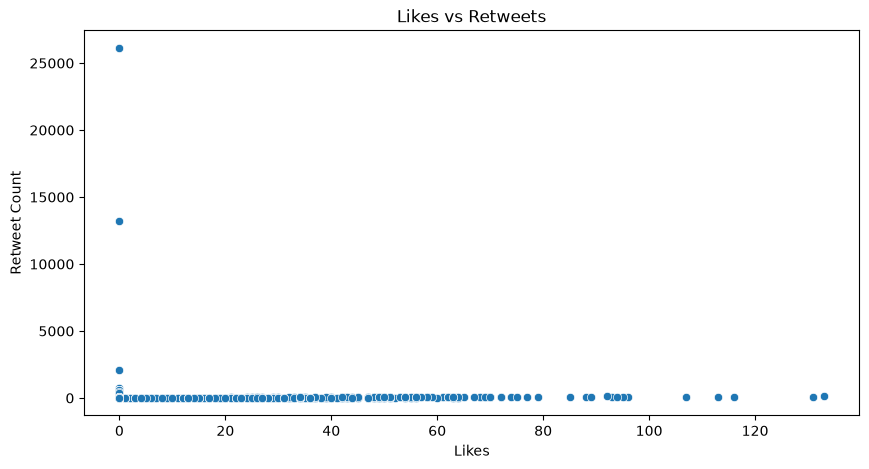

In [ ]:
plt.figure(figsize=(10, 5))

sns.scatterplot(
    data=df,
    x="Likes",
    y="RetweetCount"
)

plt.title("Likes vs Retweets")
plt.xlabel("Likes")
plt.ylabel("Retweet Count")

plt.savefig(
    "../outputs/plots/likes_vs_retweets.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
engagement_by_sentiment = df.groupby("sentiment_label")[
    ["Likes", "RetweetCount", "Reach"]
].mean()

print("Average Engagement by Sentiment:")
print(engagement_by_sentiment)

Average Engagement by Sentiment:
                    Likes  RetweetCount        Reach
sentiment_label                                     
Negative         0.064389      5.797713  6162.447182
Neutral          0.154927      7.708554  7699.105076
Positive         0.157591      8.578129  9452.963166


In [ ]:
from collections import Counter

all_words = " ".join(df["cleaned_text"]).split()

word_counts = Counter(all_words)

print("Total words:", len(all_words))
print("Unique words:", len(word_counts))

Total words: 860152
Unique words: 34824


In [ ]:
top_words = word_counts.most_common(20)

print("Top 20 Most Frequent Words:")

for word, count in top_words:
    print(word, ":", count)

Top 20 Most Frequent Words:
aws : 65589
rt : 37816
amazon : 19607
cloud : 13631
services : 12838
web : 11420
new : 8109
amp : 7106
lambda : 5412
engineer : 4749
data : 4560
google : 4380
via : 3892
service : 3812
using : 3736
blog : 3693
free : 3346
learn : 3340
azure : 3330
hiring : 2927


In [ ]:
top_words_df = pd.DataFrame(
    top_words,
    columns=["Word", "Frequency"]
)

print(top_words_df)

        Word  Frequency
0        aws      65589
1         rt      37816
2     amazon      19607
3      cloud      13631
4   services      12838
5        web      11420
6        new       8109
7        amp       7106
8     lambda       5412
9   engineer       4749
10      data       4560
11    google       4380
12       via       3892
13   service       3812
14     using       3736
15      blog       3693
16      free       3346
17     learn       3340
18     azure       3330
19    hiring       2927


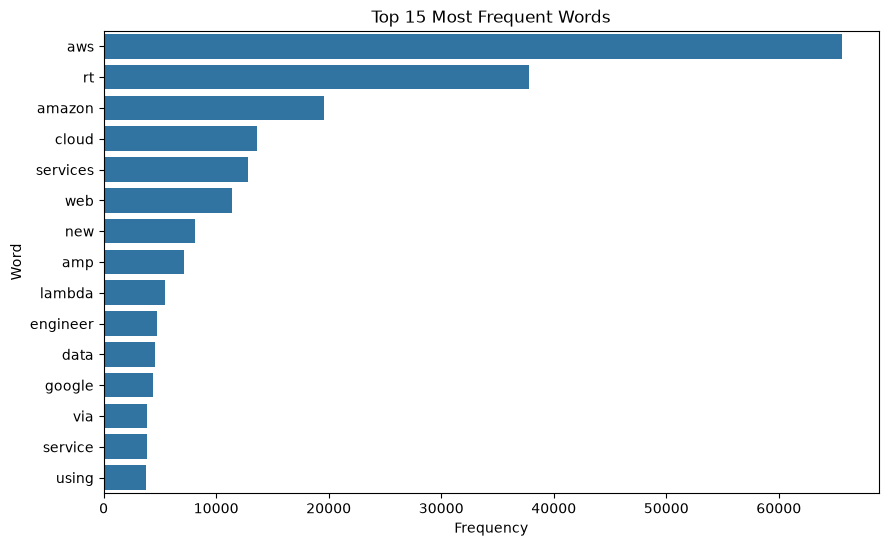

In [ ]:
top_15_words = top_words_df.head(15)

plt.figure(figsize=(10, 6))

sns.barplot(
    data=top_15_words,
    x="Frequency",
    y="Word"
)

plt.title("Top 15 Most Frequent Words")
plt.xlabel("Frequency")
plt.ylabel("Word")

plt.savefig(
    "../outputs/plots/top_15_words.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [ ]:
top_words_df.to_csv(
    "../outputs/top_20_words.csv",
    index=False
)

print("Top-word analysis saved successfully.")

Top-word analysis saved successfully.


In [ ]:
processed_path = "../data/processed/tweets_processed.csv"

df.to_csv(
    processed_path,
    index=False
)

print("Processed dataset saved successfully.")
print("Path:", processed_path)

Processed dataset saved successfully.
Path: ../data/processed/tweets_processed.csv


In [ ]:
import os

print("File exists:", os.path.exists(processed_path))

if os.path.exists(processed_path):
    print("File size (MB):", round(os.path.getsize(processed_path) / (1024 * 1024), 2))

File exists: True
File size (MB): 45.21


In [ ]:
processed_df = pd.read_csv(processed_path)

print("Saved dataset loaded successfully.")
print("Rows:", processed_df.shape[0])
print("Columns:", processed_df.shape[1])

Saved dataset loaded successfully.
Rows: 102062
Columns: 24


In [ ]:
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

print("LDA libraries imported successfully.")

LDA libraries imported successfully.


In [ ]:
df["clean_text"] = df["cleaned_text"]

print("clean_text column created.")
print(df[["cleaned_text", "clean_text"]].head())

clean_text column created.
                                                           cleaned_text  \
0                         rt innovation lab officially open click learn   
1                      open aws asia pacific seoul region via rsysadmin   
2       beginners guide scaling million users amazons aws via rsysadmin   
3                 bridging aws azure environments via vpn via rsysadmin   
4  elk aws elasticsearch service elasticbeanstalk laravel via rsysadmin   

                                                             clean_text  
0                         rt innovation lab officially open click learn  
1                      open aws asia pacific seoul region via rsysadmin  
2       beginners guide scaling million users amazons aws via rsysadmin  
3                 bridging aws azure environments via vpn via rsysadmin  
4  elk aws elasticsearch service elasticbeanstalk laravel via rsysadmin  


In [ ]:
n_topics = 5

In [ ]:
vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1,2)
)

In [ ]:
X = vectorizer.fit_transform(df['clean_text'].astype(str))

In [ ]:
print("Document-term matrix created.")
print("Shape:", X.shape)

Document-term matrix created.
Shape: (102062, 16603)


In [ ]:
lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

In [ ]:
lda.fit(X)

,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",5
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",10
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


In [ ]:
terms = vectorizer.get_feature_names_out()

In [ ]:
def print_topics(model, feature_names, no_top_words=12):
    for topic_idx, topic in enumerate(model.components_):
        print("\nTopic %d:" % (topic_idx+1))
        top_features_ind = topic.argsort()[:-no_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        top_weights = topic[top_features_ind]
        print(" | ".join(top_features))

In [ ]:
print_topics(lda, terms, no_top_words=12)


Topic 1:
amazon | aws | web | services | rt | web services | amazon web | amp | cloud | lambda | google | apple

Topic 2:
aws | rt | cloud | google | lambda | azure | aws lambda | amazon | new | engineer | devops | google cloud

Topic 3:
aws | rt | cloud | new | services | data | instances | big | amazon | blog | architect | developers

Topic 4:
aws | rt | new | amazon | blog | using | service | engineer | cloud | seattle | migration | jobs

Topic 5:
aws | rt | amazon | services | web | web services | amazon web | amp | lambda | free | aws lambda | years


In [ ]:
url_pattern = r'https?://\S+'
mention_pattern = r'@\w+'
hashtag_pattern = r'#\w+'

stop_words = set(stopwords.words('english'))

In [ ]:
from wordcloud import STOPWORDS

In [ ]:
stop_words.update(STOPWORDS)
stop_words.update(['rt', 'amp'])

In [ ]:
import re
import string

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from wordcloud import STOPWORDS

print("Section 8 libraries loaded successfully.")

Section 8 libraries loaded successfully.


In [ ]:
url_pattern = r'https?://\S+'
mention_pattern = r'@\w+'
hashtag_pattern = r'#\w+'

stop_words = set(stopwords.words('english'))

In [ ]:
stop_words.update(STOPWORDS)
stop_words.update(['rt', 'amp'])

In [ ]:
punct_table = str.maketrans('', '', string.punctuation)

In [ ]:
def clean_text(s: str) -> str:
    if not isinstance(s, str):
        return ''
    s = s.lower()
    s = re.sub(url_pattern, ' ', s)

    # keep hashtags and mentions if we want to analyze them separately
    s = re.sub(r'[^\w\s]', ' ', s)
    s = re.sub(r'\s+', ' ', s).strip()
    return s

In [ ]:
df['clean_text'] = df['text'].astype(str).apply(clean_text)

In [ ]:
def tokenize(text):
    tokens = word_tokenize(text)
    tokens = [t for t in tokens if t.isalpha() and t not in stop_words]
    return tokens

In [ ]:
import nltk

nltk.download('punkt')
nltk.download('punkt_tab')

[nltk_data] Downloading package punkt to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Package punkt is already up-to-date!
[nltk_data] Downloading package punkt_tab to C:\Users\Kohaana
[nltk_data]     Pikle\AppData\Roaming\nltk_data...
[nltk_data]   Unzipping tokenizers\punkt_tab.zip.


True

In [ ]:
df['tokens'] = df['clean_text'].apply(lambda x: tokenize(x))

In [ ]:
print('Example tokens:')
print(df['tokens'].head().tolist())

Example tokens:
[['innovation', 'lab', 'officially', 'open', 'click', 'learn', 'tech', 'javascript', 'aws'], ['open', 'aws', 'asia', 'pacific', 'seoul', 'region', 'via', 'sysadmin'], ['beginner', 'guide', 'scaling', 'million', 'users', 'amazon', 'aws', 'via', 'sysadmin'], ['bridging', 'aws', 'azure', 'environments', 'via', 'vpn', 'via', 'sysadmin'], ['elk', 'aws', 'elasticsearch', 'service', 'elasticbeanstalk', 'laravel', 'via', 'sysadmin']]


In [ ]:
n_topics = 5

In [ ]:
vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1,2)
)

In [ ]:
X = vectorizer.fit_transform(df['clean_text'].astype(str))

In [ ]:
lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

In [ ]:
lda.fit(X)

,"n_components n_components: int, default=10Number of topics... versionchanged:: 0.19 ``n_topics`` was renamed to ``n_components``",5
,"random_state random_state: int, RandomState instance or None, default=NonePass an int for reproducible results across multiple function calls.See :term:`Glossary <random_state>`.",42
,"doc_topic_prior doc_topic_prior: float, default=NonePrior of document topic distribution `theta`. If the value is None,defaults to `1 / n_components`.In [1]_, this is called `alpha`.",None
,"topic_word_prior topic_word_prior: float, default=NonePrior of topic word distribution `beta`. If the value is None, defaultsto `1 / n_components`.In [1]_, this is called `eta`.",None
,"learning_method learning_method: {'batch', 'online'}, default='batch'Method used to update `_component`. Only used in :meth:`fit` method.In general, if the data size is large, the online update will be muchfaster than the batch update.Valid options:- 'batch': Batch variational Bayes method. Use all training data in each EM update. Old `components_` will be overwritten in each iteration.- 'online': Online variational Bayes method. In each EM update, use mini-batch of training data to update the ``components_`` variable incrementally. The learning rate is controlled by the ``learning_decay`` and the ``learning_offset`` parameters... versionchanged:: 0.20 The default learning method is now ``""batch""``.",'batch'
,"learning_decay learning_decay: float, default=0.7It is a parameter that control learning rate in the online learningmethod. The value should be set between (0.5, 1.0] to guaranteeasymptotic convergence. When the value is 0.0 and batch_size is``n_samples``, the update method is same as batch learning. In theliterature, this is called kappa.",0.7
,"learning_offset learning_offset: float, default=10.0A (positive) parameter that downweights early iterations in onlinelearning. It should be greater than 1.0. In the literature, this iscalled tau_0.",10.0
,"max_iter max_iter: int, default=10The maximum number of passes over the training data (aka epochs).It only impacts the behavior in the :meth:`fit` method, and not the:meth:`partial_fit` method.",10
,"batch_size batch_size: int, default=128Number of documents to use in each EM iteration. Only used in onlinelearning.",128
,"evaluate_every evaluate_every: int, default=-1How often to evaluate perplexity. Only used in `fit` method.set it to 0 or negative number to not evaluate perplexity intraining at all. Evaluating perplexity can help you check convergencein training process, but it will also increase total training time.Evaluating perplexity in every iteration might increase training timeup to two-fold.",-1
,"total_samples total_samples: int, default=1e6Total number of documents. Only used in the :meth:`partial_fit` method.",1000000.0


In [ ]:
terms = vectorizer.get_feature_names_out()

In [ ]:
def print_topics(model, feature_names, no_top_words=12):
    for topic_idx, topic in enumerate(model.components_):
        print("\nTopic %d:" % (topic_idx+1))
        top_features_ind = topic.argsort()[:-no_top_words - 1:-1]
        top_features = [feature_names[i] for i in top_features_ind]
        top_weights = topic[top_features_ind]
        print(" | ".join(top_features))

In [ ]:
print_topics(lda, terms, no_top_words=12)


Topic 1:
aws | amazon | job | rt | engineer | hiring | services | devops | cloud | awscloud | new | jobs

Topic 2:
aws | rt | cloud | awscloud | amazon | google | rt awscloud | amp | service | learn | azure | using

Topic 3:
aws | rt | awscloud | lambda | aws lambda | cloud | rt awscloud | amp | amazon | new | serverless | blog

Topic 4:
aws | amazon | services | web | amazon web | web services | rt | cloud | jobs | 10 | seattle | seattle wa

Topic 5:
aws | rt | amazon | cloud | data | services | azure | web | amazon web | web services | awscloud | rt awscloud


In [ ]:
import sklearn
import pandas
import numpy

print("scikit-learn:", sklearn.__version__)
print("pandas:", pandas.__version__)
print("numpy:", numpy.__version__)

scikit-learn: 1.9.1
pandas: 3.0.6
numpy: 2.5.3


In [ ]:
print("X shape:", X.shape)
print("Vocabulary size:", len(terms))

X shape: (102062, 21134)
Vocabulary size: 21134


In [ ]:
doc_topic = lda.transform(X)

In [ ]:
df_topics = pd.DataFrame(
    doc_topic,
    columns=[f'Topic_{i+1}' for i in range(n_topics)]
)

In [ ]:
print("Topic probability DataFrame shape:", df_topics.shape)
print(df_topics.head()) 

Topic probability DataFrame shape: (102062, 5)
    Topic_1   Topic_2   Topic_3   Topic_4   Topic_5
0  0.008399  0.966302  0.008431  0.008399  0.008469
1  0.015460  0.112131  0.841520  0.015414  0.015474
2  0.011192  0.171653  0.794702  0.011234  0.011219
3  0.022312  0.266846  0.665726  0.022285  0.022831
4  0.020087  0.545113  0.394660  0.020042  0.020097


In [ ]:
df = pd.concat(
    [df.reset_index(drop=True), df_topics.reset_index(drop=True)],
    axis=1
)

In [ ]:
print("Updated DataFrame shape:", df.shape)
print(df.columns.tolist())

Updated DataFrame shape: (102062, 31)
['Unnamed: 0', 'UserID', 'Gender', 'LocationID', 'City', 'State', 'StateCode', 'Country', 'TweetID', 'Hour', 'Day', 'Weekday', 'IsReshare', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'Lang', 'text', 'cleaned_text', 'vader_scores', 'compound_score', 'sentiment_label', 'clean_text', 'tokens', 'Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']


In [ ]:
dominant_topic = df[[f'Topic_{i+1}' for i in range(n_topics)]].idxmax(axis=1)

In [ ]:
print('\nDominant topic counts:')
print(dominant_topic.value_counts())


Dominant topic counts:
Topic_2    34638
Topic_3    22753
Topic_1    16894
Topic_4    16052
Topic_5    11725
Name: count, dtype: int64


In [ ]:
df[["text", "cleaned_text"]].head()

,text,cleaned_text
0,"""RT @AdrianRusso82: Our Innovation Lab is officially open! Click below to learn more! https://ww...",rt innovation lab officially open click learn
1,Now Open AWS Asia Pacific (Seoul) Region via /r/sysadmin https://www.reddit.com/r/sysadmin/comm...,open aws asia pacific seoul region via rsysadmin
2,A Beginner's Guide to Scaling to 11 Million+ Users on Amazon's AWS via /r/sysadmin https://www.r...,beginners guide scaling million users amazons aws via rsysadmin
3,Bridging AWS and Azure environments via VPN via /r/sysadmin https://www.reddit.com/r/sysadmin/co...,bridging aws azure environments via vpn via rsysadmin
4,ELK on AWS ElasticSearch Service + ElasticBeanstalk + Laravel via /r/sysadmin https://www.reddit...,elk aws elasticsearch service elasticbeanstalk laravel via rsysadmin


In [ ]:
if 'Sentiment' in df.columns:

    # Group by dominant topic vs sentiment distribution
    df['dominant_topic'] = df[[f'Topic_{i+1}' for i in range(n_topics)]].idxmax(axis=1)

    cros = pd.crosstab(df['dominant_topic'], df['Sentiment'])

    display(cros)

Sentiment,-6.000000,-5.000000,-4.666667,-4.500000,-4.333333,-4.000000,-3.666667,-3.500000,-3.333333,-3.000000,-2.750000,-2.666667,-2.500000,-2.333333,-2.250000,-2.200000,-2.166667,-2.000000,-1.833333,-1.750000,-1.666667,-1.600000,-1.500000,-1.400000,-1.333333,-1.250000,-1.200000,-1.000000,-0.875000,-0.750000,-0.700000,-0.666667,-0.650000,-0.625000,-0.600000,-0.555556,-0.500000,-0.475439,-0.450000,-0.444826,-0.429462,-0.416667,-0.400000,-0.390000,-0.350000,-0.335625,-0.333333,-0.300000,-0.280000,-0.274000,-0.271462,-0.266667,-0.260000,-0.250000,-0.240000,-0.230000,-0.214000,-0.210000,-0.205714,-0.202500,-0.200000,-0.192000,-0.190175,-0.180000,-0.172129,-0.170000,-0.168000,-0.166667,-0.160000,-0.159669,-0.159000,-0.146667,-0.145000,-0.140000,-0.135000,-0.125000,-0.122903,-0.120000,-0.106667,-0.100000,-0.099047,-0.096624,-0.092000,-0.080000,-0.075000,-0.066667,-0.061452,-0.060000,-0.053333,-0.050000,-0.047500,-0.046875,-0.040000,-0.033000,-0.030000,-0.020000,-0.015088,-0.013333,-0.013100,-0.007500,-0.005697,0.000000,0.002132,0.004912,0.010000,0.013333,0.016000,0.020000,0.025000,0.029611,0.030000,0.033333,0.040000,0.045333,0.046667,0.048000,0.050000,0.053333,0.057500,0.057758,0.060000,0.062500,0.071250,0.071591,0.075000,0.080000,0.087439,0.090000,0.090901,0.091429,0.093333,0.099580,0.100000,0.104667,0.105573,0.106667,0.108800,0.116667,0.119548,0.120000,0.122903,0.126000,0.130000,0.133333,0.136351,0.140000,0.141000,0.141714,0.142245,0.143419,0.146400,0.150000,0.152000,0.152500,0.155000,0.160000,0.164000,0.165000,0.166667,0.168000,0.170000,0.171429,0.172129,0.173333,0.175000,0.180000,0.186050,0.186667,0.188571,0.189281,0.190000,0.193333,0.195000,0.197500,0.200000,0.201066,0.205714,0.208104,0.210000,0.211147,0.211250,0.213333,0.215000,0.216000,0.217500,0.218182,0.220000,0.223063,0.225000,0.230000,0.233153,0.233333,0.234000,0.240000,0.245000,0.246667,0.250000,0.252000,0.256208,0.257103,0.260000,0.262318,0.264000,0.270000,0.271250,0.272000,0.272702,0.275000,0.280000,0.285108,0.288000,0.290000,0.300000,0.311452,0.312000,0.319339,0.320000,0.320645,0.322500,0.333333,0.350000,0.352500,0.356250,0.360000,0.366000,0.375000,0.390000,0.396429,0.400000,0.412500,0.417500,0.420000,0.421832,0.423529,0.450000,0.466667,0.475000,0.484089,0.487821,0.500000,0.503572,0.510000,0.512500,0.514205,0.525000,0.528125,0.540000,0.550000,0.557143,0.560000,0.566682,0.590000,0.600000,0.645000,0.666667,0.700000,0.720000,0.750000,0.783333,0.787163,0.800000,0.833333,0.875000,0.900000,0.995833,1.000000,1.050000,1.100000,1.125000,1.150000,1.166667,1.200000,1.250000,1.333333,1.350000,1.400000,1.425000,1.500000,1.575000,1.625000,1.666667,1.750000,1.800000,1.833333,2.000000,2.125000,2.166667,2.200000,2.250000,2.333333,2.400000,2.500000,2.666667,2.750000,2.833333,2.900000,3.000000,3.166667,3.250000,3.333333,3.500000,3.666667,4.000000,4.333333,4.500000,5.000000,6.000000,6.333333,7.333333
dominant_topic,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Topic_1,0,0,0,0,0,9,0,0,0,15,0,6,7,35,0,0,0,130,0,0,0,0,38,0,1,0,0,173,0,0,0,1,1,0,5,0,9,0,0,0,0,0,0,0,0,0,2,12,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,20,0,1,0,0,0,0,13,0,0,0,0,1,0,0,3,0,37,0,0,0,1,0,1,13706,0,0,0,0,0,1,0,0,0,0,0,0,0,0,1,0,0,1,4,0,0,1,0,5,0,0,0,0,0,0,1,0,2,0,0,1,0,4,0,0,0,0,0,2,0,0,0,0,0,49,0,0,0,6,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,2,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,8,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,3,0,0,1,5,0,0,0,1,0,0,7,0,0,0,0,0,1,0,0,38,0,0,1,0,0,1,0,0,0,0,13,0,0,0,0,0,0,0,0,0,0,0,0,4,0,1,0,0,1,0,0,0,0,0,0,0,983,1,0,2,0,0,0,0,2,0,0,0,112,0,0,20,19,0,0,876,0,0,0,3,0,0,38,6,1,0,0,283,0,0,1,3,0,144,0,1,4,0,0,0
Topic_2,1,1,0,2,1,91,2,9,1,365,2,10,51,9,2,1,1,752,1,2,16,1,105,0,8,7,1,772,1,11,1,34,0,3,5,1,172,0,1,0,0,1,5,0,0,0,48,26,6,2,1

In [ ]:
cros = pd.crosstab(df['dominant_topic'], df['Sentiment'])

In [ ]:
topic_engage = df.groupby('dominant_topic')[['Likes', 'RetweetCount']].mean().reset_index()

In [ ]:
topic_engage = df.groupby('dominant_topic')[['Likes', 'RetweetCount']].mean().reset_index()

In [ ]:
print(topic_engage)

  dominant_topic     Likes  RetweetCount
0        Topic_1  0.077720      5.174441
1        Topic_2  0.121168      6.709192
2        Topic_3  0.239089     11.353843
3        Topic_4  0.111699     11.380326
4        Topic_5  0.216119      4.630448


In [ ]:
import plotly
print("Plotly version:", plotly.__version__)


Plotly version: 7.1.0


In [ ]:
import plotly.express as px

print("Plotly Express imported successfully.")

Plotly Express imported successfully.


In [ ]:
if not topic_engage.empty:
    fig = px.bar(
        topic_engage,
        x='dominant_topic',
        y=['Likes', 'RetweetCount'],
        barmode='group',
        title='Avg engagement by dominant topic'
    )
    fig.update_yaxes(type='log')
    fig.show()

    fig.write_html("../outputs/plots/topic_engagement_by_dominant_topic.html")
print("Topic engagement chart saved successfully.")

Topic engagement chart saved successfully.


Numeric columns used for correlation: ['Unnamed: 0', 'LocationID', 'Hour', 'Day', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'compound_score', 'Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']


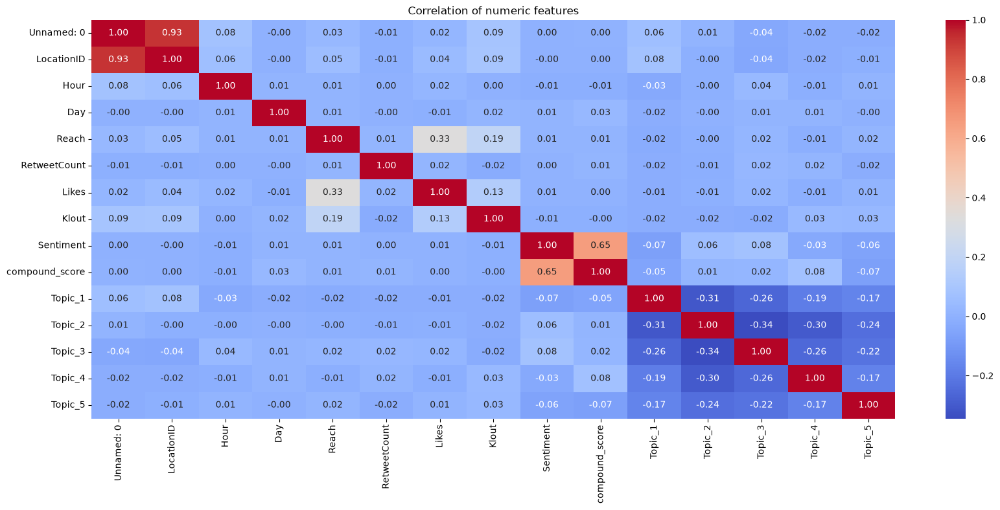

In [ ]:
numeric_cols = [c for c in df.columns if df[c].dtype in [np.float64, np.int64]]
print('Numeric columns used for correlation:', numeric_cols)

if len(numeric_cols) >= 2:
    plt.figure(figsize=(20,8))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation of numeric features')
    plt.show()

Numeric columns used for correlation: ['Unnamed: 0', 'LocationID', 'Hour', 'Day', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'compound_score', 'Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']


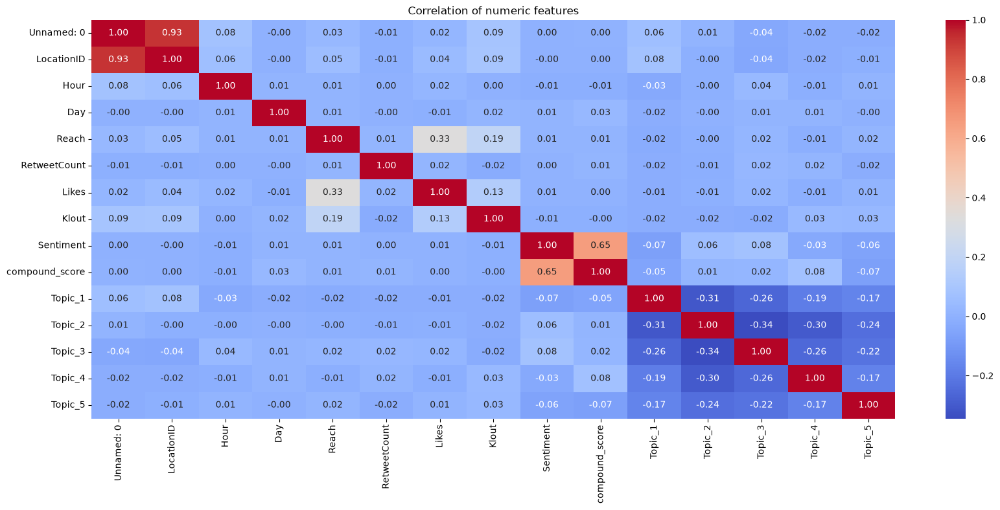

In [ ]:
numeric_cols = [c for c in df.columns if df[c].dtype in [np.float64, np.int64]]
print('Numeric columns used for correlation:', numeric_cols)

if len(numeric_cols) >= 2:
    plt.figure(figsize=(20,8))
    sns.heatmap(df[numeric_cols].corr(), annot=True, cmap='coolwarm', fmt='.2f')
    plt.title('Correlation of numeric features')
    plt.show()

In [ ]:
for col in ['RetweetCount', 'Likes']:
    if col in df.columns:
        df[f'log1p_{col}'] = np.log1p(df[col].fillna(0))

In [ ]:
if 'Hour' in df.columns:
    df['Hour_num'] = pd.to_numeric(df['Hour'], errors='coerce') 

    

In [ ]:
print("New columns:")
print([
    'log1p_RetweetCount',
    'log1p_Likes',
    'Hour_num'
])

New columns:
['log1p_RetweetCount', 'log1p_Likes', 'Hour_num']


In [ ]:
print(df[['RetweetCount', 'log1p_RetweetCount',
          'Likes', 'log1p_Likes',
          'Hour', 'Hour_num']].head())

   RetweetCount  log1p_RetweetCount  Likes  log1p_Likes  Hour  Hour_num
0         127.0             4.85203    0.0          0.0     7         7
1           0.0             0.00000    0.0          0.0    11        11
2           0.0             0.00000    0.0          0.0     6         6
3           0.0             0.00000    0.0          0.0    10        10
4           0.0             0.00000    0.0          0.0     9         9


Numeric columns used for correlation: ['Unnamed: 0', 'LocationID', 'Hour', 'Day', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'compound_score', 'Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5', 'log1p_RetweetCount', 'log1p_Likes', 'Hour_num']


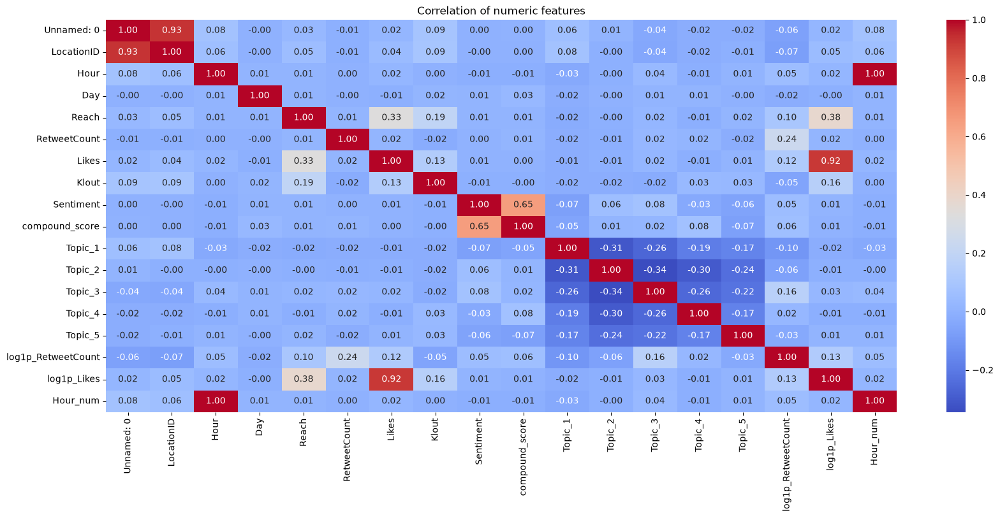

In [ ]:
numeric_cols = [c for c in df.columns if df[c].dtype in [np.float64, np.int64]]
print('Numeric columns used for correlation:', numeric_cols)

if len(numeric_cols) >= 2:
    plt.figure(figsize=(20,8))
    sns.heatmap(
        df[numeric_cols].corr(),
        annot=True,
        cmap='coolwarm',
        fmt='.2f'
    )
    plt.title('Correlation of numeric features')
    plt.show()

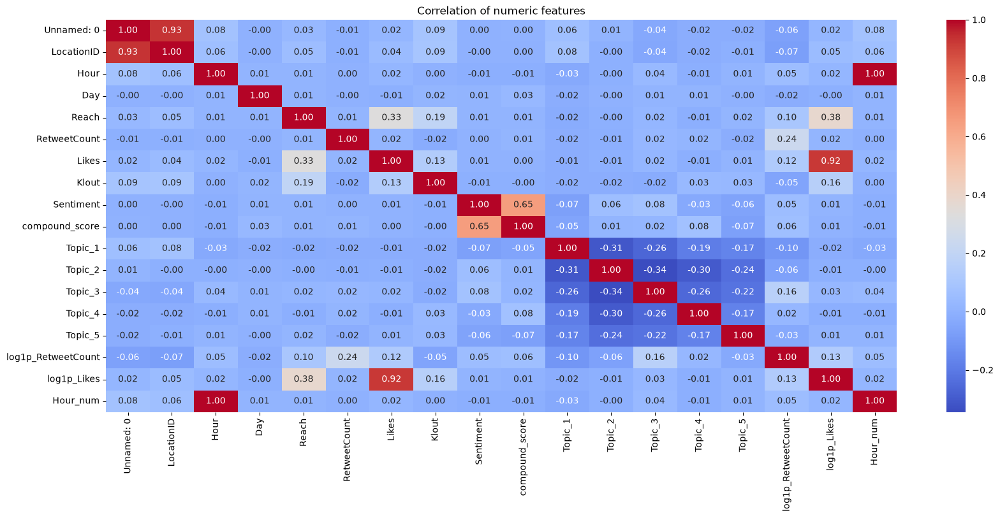

Correlation heatmap saved successfully.


In [ ]:
plt.figure(figsize=(20, 8))

sns.heatmap(
    df[numeric_cols].corr(),
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation of numeric features')

plt.savefig(
    "../outputs/plots/correlation_heatmap.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Correlation heatmap saved successfully.")

In [ ]:
output_dir = "../outputs/bda_nlp_outputs"
os.makedirs(output_dir, exist_ok=True)

In [ ]:
df.sample(200).to_csv(
    os.path.join(output_dir, 'sample_processed_tweets.csv'),
    index=False
)

In [ ]:
with open(
    os.path.join(output_dir, 'lda_topics.txt'),
    'w',
    encoding='utf-8'
) as f:
    for i, topic in enumerate(lda.components_):
        top_idx = topic.argsort()[:-12 - 1:-1]
        top_words = [terms[j] for j in top_idx]
        f.write(f'Topic {i+1}: ' + ' | '.join(top_words) + '\n')

print('Saved processed sample and topic summary to', output_dir)

Saved processed sample and topic summary to ../outputs/bda_nlp_outputs


In [ ]:
print("Files saved:")
print(os.listdir(output_dir))

Files saved:
['lda_topics.txt', 'sample_processed_tweets.csv']


In [ ]:
import os
import sys
import math
from collections import Counter
import re
import string

import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from wordcloud import WordCloud, STOPWORDS

import nltk
from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.util import ngrams

from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

import seaborn as sns

%matplotlib inline
plt.rcParams['figure.figsize'] = (12, 6)

pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 400)

print("Section 1 setup completed.")

Section 1 setup completed.


In [156]:
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')

try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')

In [157]:
if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"Dataset not found: {DATA_PATH}"
    )

print("Dataset exists:", os.path.exists(DATA_PATH))

Dataset exists: True


In [158]:
orig_cols = df.columns.tolist()

df.columns = [c.strip() for c in df.columns]

print("Column names standardized.")

Column names standardized.


In [159]:
expected = [
    'text',
    'Likes',
    'RetweetCount',
    'Sentiment',
    'Timestamp',
    'Weekday',
    'Hour',
    'Gender'
]

print(
    "Missing expected columns (if any):",
    [c for c in expected if c not in df.columns]
)

Missing expected columns (if any): ['Timestamp']


In [160]:
for col in ['Likes', 'RetweetCount', 'Sentiment']:
    if col in df.columns:
        df[col] = pd.to_numeric(df[col], errors='coerce')

print("Numeric columns checked.")

Numeric columns checked.


In [161]:
if 'Timestamp' in df.columns:
    df['Timestamp'] = pd.to_datetime(
        df['Timestamp'],
        errors='coerce'
    )

print("Timestamp check completed.")

Timestamp check completed.


In [162]:
df = df[df['text'].notnull()].copy()

In [163]:
print("\nAfter cleaning shape:", df.shape)


After cleaning shape: (102062, 24)


In [164]:
if 'Likes' in df.columns:
    display(
        df.nlargest(10, 'Likes')[
            ['text', 'Likes', 'RetweetCount', 'Sentiment']
        ]
    )

,text,Likes,RetweetCount,Sentiment
59720,Now easily provision manage &amp; deploy SSL/TLS certificates with AWS Certificate Manager. https://aws.amazon.com/blogs/aws/new-aws-certificate-manager-deploy-ssltls-based-apps-on-aws/?sc_channel=sm&sc_campaign=launches_2016&sc_publisher=tw_go&sc_content=ga&sc_country=global&sc_geo=global&sc_category=certificate_manager&adbsc=social_launches_20160121_57489256 http://twitter.com/awscloud/statu...,133.0,157.0,0.0
59575,Use a highly available NAT gateway to give private subnets outbound Internet access: http://docs.aws.amazon.com/AmazonVPC/latest/UserGuide/vpc-nat-gateway.html?adbsc=docs_20160102_56673526&adbid=683367429049683968&adbpl=tw&adbpr=66780587 http://twitter.com/awscloud/status/683367429049683968/photo/1,131.0,85.0,0.0
59589,New AWS Startup Blog: Hiring a Cloud Engineer? Questions to Ask and What You Should Hear https://medium.com/@awsactivate/hiring-a-cloud-engineer-questions-to-ask-and-what-you-should-hear-12a960d97163?adbsc=social_20160105_56960756#.7x81tes9r http://twitter.com/awscloud/status/684504909362806785/photo/1,116.0,73.0,0.0
59905,New on the AWS #BigData blog: Big Data Analytics Options on AWS: Updated White Paper http://blogs.aws.amazon.com/bigdata/post/Tx2XAKHXB8GJKLT/Big-Data-Analytics-Options-on-AWS-Updated-White?adbsc=social_blogs_20160212_58244596&adbid=698238715718668288&adbpl=tw&adbpr=66780587 http://twitter.com/awscloud/status/698238715718668288/photo/1,113.0,105.0,0.0
60193,Auto Scaling now sends events to CloudWatch Events when it executes lifecycle hooks: http://docs.aws.amazon.com/AutoScaling/latest/DeveloperGuide/cloud-watch-events.html?adbsc=docs_20160312_58807086&adbid=708732826577817600&adbpl=tw&adbpr=66780587 http://twitter.com/awscloud/status/708732826577817600/photo/1,107.0,94.0,0.0
59637,New on the AWS Startup Blog: Scaling on AWS (Part 4) : &gt; One Million Users https://medium.com/aws-activate-startup-blog/scaling-on-aws-part-4-one-million-users-82ae773a55cc?adbsc=social_20160113_57182946&adbid=687076354022481924&adbpl=tw&adbpr=66780587#.mc3s306rw http://twitter.com/awscloud/status/687076354022481924/photo/1,96.0,44.0,0.0
59735,New on the AWS #BigData Blog! Agile Analytics with Amazon Redshift http://blogs.aws.amazon.com/bigdata/post/Tx3HHDIXCZFDGTN/Agile-Analytics-with-Amazon-Redshift?adbsc=social_blogs_20160122_57524276&adbid=690669105825722368&adbpl=tw&adbpr=66780587 http://twitter.com/awscloud/status/690669105825722368/photo/1,95.0,63.0,0.0
59838,How to deploy an SSL certificate from AWS Certificate Manager to your load balancer: http://docs.aws.amazon.com/ElasticLoadBalancing/latest/DeveloperGuide/ssl-server-cert.html?adbsc=docs_20160206_57688156&adbid=696049540370071552&adbpl=tw&adbpr=66780587 http://twitter.com/awscloud/status/696049540370071552/photo/1,94.0,69.0,0.0
59703,New on the AWS Startup Blog - Simple Drone Service: From Idea to re:Invent https://medium.com/aws-activate-startup-blog/simple-drone-service-from-idea-to-re-invent-da13e5084e4?adbsc=social_20160119_57405906#.tkpnvdv1x http://twitter.com/awscloud/status/689587904528560128/photo/1,93.0,64.0,0.0
60172,VP of #AWS &amp; Distinguished Engineer James Hamilton recaps a decade of innovation: http://perspectives.mvdirona.com/2016/03/a-decade-of-innovation/?adbsc=social_blogs_20160310_59186006 http://twitter.com/awscloud/status/707969805387599873/photo/1,92.0,119.0,1.0


In [165]:
if 'RetweetCount' in df.columns:
    display(
        df.nlargest(10, 'RetweetCount')[
            ['text', 'Likes', 'RetweetCount', 'Sentiment']
        ]
    )

,text,Likes,RetweetCount,Sentiment
98345,RT @Chargers: soo hungry need to find my wife and head to pf changs,0.0,26127.0,0.0
100722,RT @2319guy: if I had this set of teeth I wouldn't even bother talking I'd just smile until I die http://twitter.com/2319guy/status/679083779491692549/photo/1,0.0,13195.0,-1.0
100723,RT @LifeWithAlcohol: Spring break forecast http://twitter.com/LifeWithAlcohol/status/707775679253782529/photo/1,0.0,2065.0,0.0
60084,Test your iOS Android &amp; web apps against real phones and tablets on AWS. Start today for free! https://cards.twitter.com/cards/13rc8b/1ihbc,0.0,782.0,1.0
59832,Learn how to set up Parse Server on AWS using Elastic Beanstalk. https://cards.twitter.com/cards/13rc8b/1fmu6,0.0,637.0,0.0
86818,RT @planetepics: Barcelona as seen from a helicopter by Tim Orr http://twitter.com/planetepics/status/706623488090513409/photo/1,0.0,632.0,0.0
59605,Follow us for the lastest cloud computing news &amp; updates!,0.0,620.0,0.0
29258,RT @awscloud: Learn how to set up Parse Server on AWS using Elastic Beanstalk. https://cards.twitter.com/cards/13rc8b/1fmu6,0.0,616.0,0.0
101715,RT @awscloud: Learn how to set up Parse Server on AWS using Elastic Beanstalk. https://cards.twitter.com/cards/13rc8b/1fmu6,0.0,605.0,0.0
38421,RT @awscloud: Learn how to set up Parse Server on AWS using Elastic Beanstalk. https://cards.twitter.com/cards/13rc8b/1fmu6,0.0,596.0,0.0


In [166]:
for c in ['Weekday', 'Hour', 'Gender', 'Sentiment']:
    if c in df.columns:
        print(f"\nTop counts for {c}:")
        print(df[c].value_counts().head(10))


Top counts for Weekday:
Weekday
Tuesday      18826
Thursday     18819
Wednesday    18578
Monday       15746
Friday       15273
Saturday      7636
Sunday        7184
Name: count, dtype: int64

Top counts for Hour:
Hour
11    6274
10    6255
9     6051
12    5912
13    5432
8     5415
14    5315
15    5202
7     5000
16    4772
Name: count, dtype: int64

Top counts for Gender:
Gender
Male       52603
Unknown    30003
Female     10087
Unisex      9369
Name: count, dtype: int64

Top counts for Sentiment:
Sentiment
 0.0    68763
 1.0     8951
 2.0     8755
 3.0     4024
-1.0     1802
-2.0     1764
 1.5     1184
 4.0      814
 2.5      704
 0.5      565
Name: count, dtype: int64


In [172]:
if 'Sentiment' in df.columns:
    if df['Sentiment'].dtype == 'O' or df['Sentiment'].nunique() < 10:
        fig = px.histogram(
            df,
            x='Sentiment',
            color='Sentiment',
            title='Sentiment Distribution',
            barmode='group'
        )
    else:
        fig = px.histogram(
            df,
            x='Sentiment',
            nbins=50,
            title='Sentiment Distribution (numeric)'
        )
    fig.show()

    fig.write_image("../outputs/plots/sentiment_distribution_numeric.png")


RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


In [169]:
%pip install kaleido



   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------------------------------------- 0/4 [simplejson]
   ---------- ----------------------------- 1/4 [logistro]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   -------------------- ------------------- 2/4 [choreographer]
   ------------------------------ --------- 3/4 [kaleido]
   ------------------------------ --------- 3/4 [kaleido]
   ---------------------------------------- 4/4 [kaleido]

Note: you may need to restart the kernel to use updated packages.


RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


In [173]:
if 'Sentiment' in df.columns:
    if df['Sentiment'].dtype == 'O' or df['Sentiment'].nunique() < 10:
        fig = px.histogram(
            df,
            x='Sentiment',
            color='Sentiment',
            title='Sentiment Distribution',
            barmode='group'
        )
    else:
        fig = px.histogram(
            df,
            x='Sentiment',
            nbins=50,
            title='Sentiment Distribution (numeric)'
        )
    fig.show()

    fig.write_image("../outputs/plots/sentiment_distribution_numeric.png")

print("Chart saved successfully.")
print("../outputs/plots/sentiment_distribution_numeric.png")

RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


In [174]:
%pip install -U kaleido

Note: you may need to restart the kernel to use updated packages.


In [175]:
fig.write_image("../outputs/plots/sentiment_distribution_numeric.png")

print("Saved to outputs/plots/")

RuntimeError: 
Image export requires the Kaleido package, v1.0.0 or greater,
which can be installed using pip:

    $ pip install --upgrade "kaleido>=1"


In [176]:
for col in ['RetweetCount', 'Likes']:
    if col in df.columns:
        df[f'log1p_{col}'] = np.log1p(df[col].fillna(0))

In [177]:
print(df[['RetweetCount', 'log1p_RetweetCount',
          'Likes', 'log1p_Likes']].head())

   RetweetCount  log1p_RetweetCount  Likes  log1p_Likes
0         127.0             4.85203    0.0          0.0
1           0.0             0.00000    0.0          0.0
2           0.0             0.00000    0.0          0.0
3           0.0             0.00000    0.0          0.0
4           0.0             0.00000    0.0          0.0


In [181]:
for col in ['log1p_RetweetCount', 'log1p_Likes']:
    if col in df.columns:
        fig = px.histogram(
            df,
            x=col,
            nbins=50,
            title=f'{col} Distribution (log1p)'
        )
        fig.show()
        

In [182]:
import os

os.makedirs("../outputs/plots", exist_ok=True)

for col in ['log1p_RetweetCount', 'log1p_Likes']:
    if col in df.columns:
        fig = px.histogram(
            df,
            x=col,
            nbins=50,
            title=f'{col} Distribution (log1p)'
        )

        fig.show()

        filename = f"../outputs/plots/{col}_distribution.html"
        fig.write_html(filename)

        print("Saved:", filename)

Saved: ../outputs/plots/log1p_RetweetCount_distribution.html


Saved: ../outputs/plots/log1p_Likes_distribution.html


In [179]:
for col in ['RetweetCount', 'Likes']:
    if col in df.columns:
        df[f'log1p_{col}'] = np.log1p(df[col].fillna(0))

In [183]:
%pip install -U kaleido

Note: you may need to restart the kernel to use updated packages.


In [1]:
import os
import sys
import math
from collections import Counter
import re
import string

In [2]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

from wordcloud import WordCloud, STOPWORDS

In [3]:
import nltk

from nltk.corpus import stopwords
from nltk.tokenize import word_tokenize
from nltk.util import ngrams

from sklearn.decomposition import LatentDirichletAllocation
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer

In [4]:
import seaborn as sns

In [5]:
%matplotlib inline

plt.rcParams['figure.figsize'] = (12, 6)

In [6]:
try:
    nltk.data.find('tokenizers/punkt')
except LookupError:
    nltk.download('punkt')

try:
    nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('stopwords')

In [7]:
pd.set_option('display.max_columns', None)
pd.set_option('display.max_colwidth', 400)

print("Section 1 setup completed.")

Section 1 setup completed.


In [8]:
db_path = "../data/raw/tweets-engagement-metrics.csv"

In [9]:
if not os.path.exists(db_path):
    raise FileNotFoundError(
        f"Dataset not found at {db_path}. Check the file path."
    )

print("Dataset found successfully.")

Dataset found successfully.


In [10]:
df = pd.read_csv(db_path)

print("Dataset Shape:", df.shape)

Dataset Shape: (102062, 20)


In [11]:
print("First 5 rows:")
display(df.head())

print("\nData types and information:")
df.info()

First 5 rows:


,Unnamed: 0,UserID,Gender,LocationID,City,State,StateCode,Country,TweetID,Hour,Day,Weekday,IsReshare,Reach,RetweetCount,Likes,Klout,Sentiment,Lang,text
0,0,tw-1267804344,Unknown,1.0,Elbasan,Elbasan,AL,Albania,tw-698155297102295041,7,12,Friday,True,339.0,127.0,0.0,44.0,0.0,en,"""RT @AdrianRusso82: Our Innovation Lab is officially open! Click below to learn more! https://www.linkedin.com/pulse/new-innovation-lab-open-business-adrian-russo-msis-mcp?utm_source&utm_medium&utm_campaign #Tech #JavaScript #AWS http"""
1,1,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-685159757209059329,11,7,Thursday,False,87.0,0.0,0.0,22.0,0.0,en,Now Open AWS Asia Pacific (Seoul) Region via /r/sysadmin https://www.reddit.com/r/sysadmin/comments/3zvciv/now_open_aws_asia_pacific_seoul_region/ http://twitter.com/besmirzanaj/status/685159757209059329/photo/1
2,2,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-686907710311378944,6,12,Tuesday,False,87.0,0.0,0.0,22.0,0.0,en,A Beginner's Guide to Scaling to 11 Million+ Users on Amazon's AWS via /r/sysadmin https://www.reddit.com/r/sysadmin/comments/40hon7/a_beginners_guide_to_scaling_to_11_million_users/ http://twitter.com/besmirzanaj/status/686907710311378944/photo/1
3,3,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-686968158050201600,10,12,Tuesday,False,87.0,0.0,0.0,22.0,0.0,en,Bridging AWS and Azure environments via VPN via /r/sysadmin https://www.reddit.com/r/sysadmin/comments/40mdc4/bridging_aws_and_azure_environments_via_vpn/ http://twitter.com/besmirzanaj/status/686968158050201600/photo/1
4,4,tw-27229880,Male,2.0,Tirana,Tirane,AL,Albania,tw-690210449674092545,9,21,Thursday,False,85.0,0.0,0.0,21.0,0.0,en,ELK on AWS ElasticSearch Service + ElasticBeanstalk + Laravel via /r/sysadmin https://www.reddit.com/r/sysadmin/comments/41x9hy/elk_on_aws_elasticsearch_service_elasticbeanstalk/ http://twitter.com/besmirzanaj/status/690210449674092545/photo/1



Data types and information:
<class 'pandas.DataFrame'>
RangeIndex: 102062 entries, 0 to 102061
Data columns (total 20 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   Unnamed: 0    102062 non-null  int64  
 1   UserID        102062 non-null  str    
 2   Gender        102062 non-null  str    
 3   LocationID    102062 non-null  float64
 4   City          99783 non-null   str    
 5   State         100165 non-null  str    
 6   StateCode     100336 non-null  str    
 7   Country       102062 non-null  str    
 8   TweetID       102062 non-null  str    
 9   Hour          102062 non-null  int64  
 10  Day           102062 non-null  int64  
 11  Weekday       102062 non-null  str    
 12  IsReshare     102062 non-null  bool   
 13  Reach         102062 non-null  float64
 14  RetweetCount  102062 non-null  float64
 15  Likes         102062 non-null  float64
 16  Klout         102062 non-null  float64
 17  Sentiment     102062 non-null 

In [12]:
print("Null counts:")
print(df.isnull().sum())

Null counts:
Unnamed: 0         0
UserID             0
Gender             0
LocationID         0
City            2279
State           1897
StateCode       1726
Country            0
TweetID            0
Hour               0
Day                0
Weekday            0
IsReshare          0
Reach              0
RetweetCount       0
Likes              0
Klout              0
Sentiment          0
Lang               0
text               0
dtype: int64


In [13]:
# Section 3.1 — Standardize column names

orig_cols = df.columns.tolist()

df.columns = [c.strip() for c in df.columns]

print("Column names standardized.")
print("Columns:")
print(df.columns.tolist())

Column names standardized.
Columns:
['Unnamed: 0', 'UserID', 'Gender', 'LocationID', 'City', 'State', 'StateCode', 'Country', 'TweetID', 'Hour', 'Day', 'Weekday', 'IsReshare', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'Lang', 'text']


In [14]:
# Restore the already processed 24-column dataset

processed_path = "../data/processed/tweets_processed.csv"

if not os.path.exists(processed_path):
    raise FileNotFoundError(
        f"Processed dataset not found at {processed_path}"
    )

df = pd.read_csv(processed_path)

print("Processed dataset loaded successfully.")
print("Shape:", df.shape)
print("Columns:")
print(df.columns.tolist())

Processed dataset loaded successfully.
Shape: (102062, 24)
Columns:
['Unnamed: 0', 'UserID', 'Gender', 'LocationID', 'City', 'State', 'StateCode', 'Country', 'TweetID', 'Hour', 'Day', 'Weekday', 'IsReshare', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'Lang', 'text', 'cleaned_text', 'vader_scores', 'compound_score', 'sentiment_label']


In [15]:
# Verify processed columns

required_processed_columns = [
    'cleaned_text',
    'vader_scores',
    'compound_score',
    'sentiment_label'
]

print("Checking processed columns...\n")

for col in required_processed_columns:
    print(f"{col}: {'FOUND' if col in df.columns else 'MISSING'}")

print("\nDataset shape:", df.shape)

Checking processed columns...

cleaned_text: FOUND
vader_scores: FOUND
compound_score: FOUND
sentiment_label: FOUND

Dataset shape: (102062, 24)


In [16]:
# Verify the sentiment analysis results

print("Sentiment label distribution:")
print(df['sentiment_label'].value_counts())

print("\nCompound score summary:")
print(df['compound_score'].describe())

Sentiment label distribution:
sentiment_label
Positive    48759
Neutral     45957
Negative     7346
Name: count, dtype: int64

Compound score summary:
count    102062.000000
mean          0.168318
std           0.286560
min          -0.942300
25%           0.000000
50%           0.000000
75%           0.381800
max           0.973500
Name: compound_score, dtype: float64


In [17]:
# Verify existing project outputs

import os

output_folders = [
    "../outputs/plots",
    "../outputs/wordclouds",
    "../outputs/bda_nlp_outputs"
]

for folder in output_folders:
    print(f"\n{folder}")
    if os.path.exists(folder):
        files = sorted(os.listdir(folder))
        for file in files:
            print("  ✓", file)
    else:
        print("  Folder not found")


../outputs/plots
  ✓ correlation_heatmap.png
  ✓ likes_vs_retweets.png
  ✓ log1p_Likes_distribution.html
  ✓ log1p_RetweetCount_distribution.html
  ✓ sentiment_distribution.png
  ✓ top_15_words.png
  ✓ topic_engagement_by_dominant_topic.html
  ✓ tweet_activity_by_hour.png
  ✓ tweet_activity_by_weekday.png

../outputs/wordclouds
  ✓ negative_wordcloud.png
  ✓ neutral_wordcloud.png
  ✓ positive_wordcloud.png

../outputs/bda_nlp_outputs
  ✓ lda_topics.txt
  ✓ sample_processed_tweets.csv


In [18]:
# Save PNG versions of the existing log-distribution charts

import plotly.express as px
import os

os.makedirs("../outputs/plots", exist_ok=True)

# Log Likes
fig = px.histogram(
    df,
    x="log1p_Likes",
    nbins=50,
    title="log1p_Likes Distribution (log1p)"
)

fig.write_image("../outputs/plots/log1p_Likes_distribution.png")
print("Saved: log1p_Likes_distribution.png")


# Log Retweets
fig = px.histogram(
    df,
    x="log1p_RetweetCount",
    nbins=50,
    title="log1p_RetweetCount Distribution (log1p)"
)

fig.write_image("../outputs/plots/log1p_RetweetCount_distribution.png")
print("Saved: log1p_RetweetCount_distribution.png")

ValueError: Value of 'x' is not the name of a column in 'data_frame'. Expected one of ['Unnamed: 0', 'UserID', 'Gender', 'LocationID', 'City', 'State', 'StateCode', 'Country', 'TweetID', 'Hour', 'Day', 'Weekday', 'IsReshare', 'Reach', 'RetweetCount', 'Likes', 'Klout', 'Sentiment', 'Lang', 'text', 'cleaned_text', 'vader_scores', 'compound_score', 'sentiment_label'] but received: log1p_Likes

In [19]:
# Recreate the log-transformed columns from Section 5.2

for col in ['RetweetCount', 'Likes']:
    if col in df.columns:
        df[f'log1p_{col}'] = np.log1p(df[col].fillna(0))

print("Log-transformed columns created successfully.")
print([
    col for col in ['log1p_RetweetCount', 'log1p_Likes']
    if col in df.columns
])

Log-transformed columns created successfully.
['log1p_RetweetCount', 'log1p_Likes']


In [20]:
# Save PNG versions of the log-distribution charts

import plotly.express as px
import os

os.makedirs("../outputs/plots", exist_ok=True)

# Log Likes
fig = px.histogram(
    df,
    x="log1p_Likes",
    nbins=50,
    title="log1p_Likes Distribution (log1p)"
)

fig.write_image("../outputs/plots/log1p_Likes_distribution.png")
print("Saved: log1p_Likes_distribution.png")


# Log Retweets
fig = px.histogram(
    df,
    x="log1p_RetweetCount",
    nbins=50,
    title="log1p_RetweetCount Distribution (log1p)"
)

fig.write_image("../outputs/plots/log1p_RetweetCount_distribution.png")
print("Saved: log1p_RetweetCount_distribution.png")

Saved: log1p_Likes_distribution.png
Saved: log1p_RetweetCount_distribution.png


In [21]:
# Section 6.3 — Save Weekday vs Hour heatmap

if 'Weekday' in df.columns and 'Hour_num' in df.columns:

    pivot = (
        df.pivot_table(
            index='Weekday',
            columns='Hour_num',
            values='text',
            aggfunc='count'
        )
        .reindex(ordered)
    )

    plt.figure(figsize=(14, 5))
    sns.heatmap(
        pivot,
        cmap='YlGnBu'
    )

    plt.title('Tweet Count by Weekday and Hour')
    plt.ylabel('Weekday')
    plt.xlabel('Hour')
    plt.tight_layout()

    plt.savefig(
        "../outputs/plots/tweet_activity_weekday_hour_heatmap.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved: tweet_activity_weekday_hour_heatmap.png")

In [22]:
import os

path = "../outputs/plots/tweet_activity_weekday_hour_heatmap.png"

print("Current working directory:", os.getcwd())
print("Expected file path:", os.path.abspath(path))
print("File exists:", os.path.exists(path))

Current working directory: c:\Project\SocialPulse-Analytics\notebooks
Expected file path: c:\Project\SocialPulse-Analytics\outputs\plots\tweet_activity_weekday_hour_heatmap.png
File exists: False


In [23]:
# Save Section 6.3 heatmap correctly

import os
import matplotlib.pyplot as plt
import seaborn as sns

ordered = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

pivot = (
    df.pivot_table(
        index='Weekday',
        columns='Hour_num',
        values='text',
        aggfunc='count'
    )
    .reindex(ordered)
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    pivot,
    cmap='YlGnBu'
)

plt.title('Tweet Count by Weekday and Hour')
plt.ylabel('Weekday')
plt.xlabel('Hour')
plt.tight_layout()

output_path = "../outputs/plots/tweet_activity_weekday_hour_heatmap.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", os.path.abspath(output_path))
print("File exists:", os.path.exists(output_path))

KeyError: 'Hour_num'

In [24]:
# Recreate Hour_num for Section 6.3

df['Hour_num'] = pd.to_numeric(df['Hour'], errors='coerce')

print("Hour_num created successfully.")
print(df['Hour_num'].head())

Hour_num created successfully.
0     7
1    11
2     6
3    10
4     9
Name: Hour_num, dtype: int64


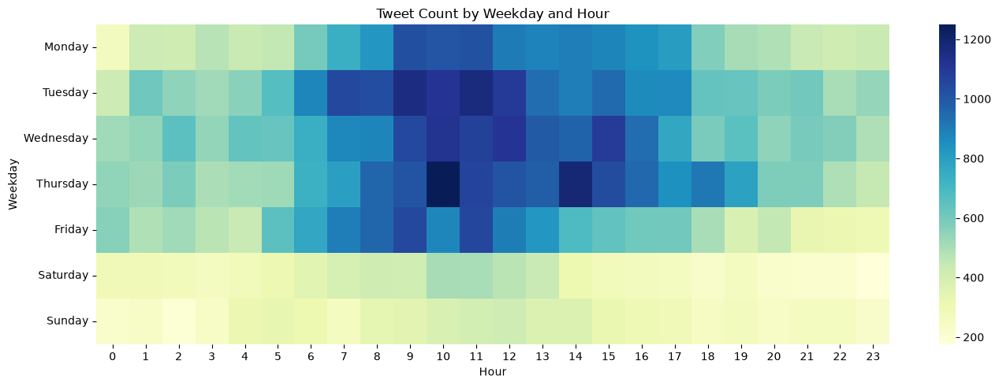

Saved: c:\Project\SocialPulse-Analytics\outputs\plots\tweet_activity_weekday_hour_heatmap.png
File exists: True


In [25]:
# Save Section 6.3 heatmap

ordered = [
    'Monday', 'Tuesday', 'Wednesday',
    'Thursday', 'Friday', 'Saturday', 'Sunday'
]

pivot = (
    df.pivot_table(
        index='Weekday',
        columns='Hour_num',
        values='text',
        aggfunc='count'
    )
    .reindex(ordered)
)

plt.figure(figsize=(14, 5))

sns.heatmap(
    pivot,
    cmap='YlGnBu'
)

plt.title('Tweet Count by Weekday and Hour')
plt.ylabel('Weekday')
plt.xlabel('Hour')
plt.tight_layout()

output_path = "../outputs/plots/tweet_activity_weekday_hour_heatmap.png"

plt.savefig(
    output_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", os.path.abspath(output_path))
print("File exists:", os.path.exists(output_path))

In [26]:
# Section 7 — Engagement vs Sentiment

for metric in ['log1p_Likes', 'log1p_RetweetCount']:
    if metric in df.columns and 'Sentiment' in df.columns:
        fig = px.box(
            df,
            x='Sentiment',
            y=metric,
            color='Sentiment',
            points='all',
            title=f'{metric} vs Sentiment'
        )
        fig.show()

In [27]:
# Section 7 — Save Engagement vs Sentiment charts as PNG

import os
import plotly.express as px

os.makedirs("../outputs/plots", exist_ok=True)

for metric in ['log1p_Likes', 'log1p_RetweetCount']:
    if metric in df.columns and 'Sentiment' in df.columns:

        fig = px.box(
            df,
            x='Sentiment',
            y=metric,
            color='Sentiment',
            points='all',
            title=f'{metric} vs Sentiment'
        )

        output_path = f"../outputs/plots/{metric}_vs_Sentiment.png"

        fig.write_image(output_path)

        print("Saved:", os.path.abspath(output_path))

Saved: c:\Project\SocialPulse-Analytics\outputs\plots\log1p_Likes_vs_Sentiment.png
Saved: c:\Project\SocialPulse-Analytics\outputs\plots\log1p_RetweetCount_vs_Sentiment.png


In [29]:
# Section 10.1 — Top Hashtags and Mentions with log-scaled Y-axis

if not hash_df.empty:
    fig = px.bar(
        hash_df.head(25),
        x='Hashtag',
        y='Count',
        title='Top Hashtags (Top 25)'
    )
    fig.update_yaxes(type='log')
    fig.show()

if not ment_df.empty:
    fig = px.bar(
        ment_df.head(25),
        x='Mention',
        y='Count',
        title='Top Mentions (Top 25)'
    )
    fig.update_yaxes(type='log')
    fig.show()

NameError: name 'hash_df' is not defined

In [30]:
# Section 10 — Hashtags & Mentions Analysis

from collections import Counter
import re
import pandas as pd
import plotly.express as px

# Patterns for hashtags and mentions
hashtag_pattern = r'#\w+'
mention_pattern = r'@\w+'

# Extract hashtags and mentions from raw tweet text
all_hashtags = Counter(
    re.findall(
        hashtag_pattern,
        ' '.join(df['text'].astype(str).tolist()).lower()
    )
)

all_mentions = Counter(
    re.findall(
        mention_pattern,
        ' '.join(df['text'].astype(str).tolist()).lower()
    )
)

# Convert to DataFrames
hash_df = pd.DataFrame(
    all_hashtags.most_common(40),
    columns=['Hashtag', 'Count']
)

ment_df = pd.DataFrame(
    all_mentions.most_common(40),
    columns=['Mention', 'Count']
)

print("Top hashtags:")
print(hash_df.head(10))

print("\nTop mentions:")
print(ment_df.head(10))

# 10.1 — Top hashtags with log-scaled Y-axis
if not hash_df.empty:
    fig = px.bar(
        hash_df.head(25),
        x='Hashtag',
        y='Count',
        title='Top Hashtags (Top 25)'
    )
    fig.update_yaxes(type='log')
    fig.show()

# 10.1 — Top mentions with log-scaled Y-axis
if not ment_df.empty:
    fig = px.bar(
        ment_df.head(25),
        x='Mention',
        y='Count',
        title='Top Mentions (Top 25)'
    )
    fig.update_yaxes(type='log')
    fig.show()

Top hashtags:
           Hashtag  Count
0             #aws  27148
1           #cloud   6736
2             #job   4390
3            #jobs   3585
4         #bigdata   2219
5          #devops   1915
6  #cloudcomputing   1832
7       #jobsearch   1594
8          #amazon   1564
9           #azure   1557

Top mentions:
          Mention  Count
0       @awscloud  14364
1       @jeffbarr   2110
2         @werner    750
3         @amazon    704
4    @awsstartups    435
5    @awsidentity    434
6   @goserverless    342
7    @botmetrichq    336
8  @tjholowaychuk    330
9     @techcrunch    328


In [31]:
# Section 10 — Save Hashtag and Mention charts as PNG

import os
import plotly.express as px

os.makedirs("../outputs/plots", exist_ok=True)

# Top Hashtags
if not hash_df.empty:
    fig = px.bar(
        hash_df.head(25),
        x='Hashtag',
        y='Count',
        title='Top Hashtags (Top 25)'
    )
    fig.update_yaxes(type='log')

    output_path = "../outputs/plots/top_hashtags.png"
    fig.write_image(output_path)

    print("Saved:", os.path.abspath(output_path))


# Top Mentions
if not ment_df.empty:
    fig = px.bar(
        ment_df.head(25),
        x='Mention',
        y='Count',
        title='Top Mentions (Top 25)'
    )
    fig.update_yaxes(type='log')

    output_path = "../outputs/plots/top_mentions.png"
    fig.write_image(output_path)

    print("Saved:", os.path.abspath(output_path))

Saved: c:\Project\SocialPulse-Analytics\outputs\plots\top_hashtags.png
Saved: c:\Project\SocialPulse-Analytics\outputs\plots\top_mentions.png


In [32]:
# Section 13 — Sentiment & Topic Cross-Analysis

if 'Sentiment' in df.columns:

    # Sentiment distribution by dominant topic
    df['dominant_topic'] = df[
        [f'Topic_{i+1}' for i in range(n_topics)]
    ].idxmax(axis=1)

    cros = pd.crosstab(
        df['dominant_topic'],
        df['Sentiment']
    )

    print("Sentiment distribution by dominant topic:")
    display(cros)

    # Average engagement by dominant topic
    topic_engage = (
        df.groupby('dominant_topic')[['Likes', 'RetweetCount']]
        .mean()
        .reset_index()
    )

    print("\nAverage engagement by dominant topic:")
    display(topic_engage)

    # Visualize topic vs average engagement
    if not topic_engage.empty:
        fig = px.bar(
            topic_engage,
            x='dominant_topic',
            y=['Likes', 'RetweetCount'],
            barmode='group',
            title='Average Engagement by Dominant Topic'
        )

        fig.update_yaxes(type='log')
        fig.show()

NameError: name 'n_topics' is not defined

In [33]:
# Section 13 — Sentiment & Topic Cross-Analysis

if 'Sentiment' in df.columns:

    # Identify the 5 topic probability columns
    topic_cols = [f'Topic_{i}' for i in range(1, 6)]

    # Find the dominant topic for each tweet
    df['dominant_topic'] = df[topic_cols].idxmax(axis=1)

    # Sentiment distribution by dominant topic
    cros = pd.crosstab(
        df['dominant_topic'],
        df['Sentiment']
    )

    print("Sentiment distribution by dominant topic:")
    display(cros)

    # Average engagement by dominant topic
    topic_engage = (
        df.groupby('dominant_topic')[['Likes', 'RetweetCount']]
        .mean()
        .reset_index()
    )

    print("\nAverage engagement by dominant topic:")
    display(topic_engage)

    # Visualize topic vs average engagement
    if not topic_engage.empty:

        fig = px.bar(
            topic_engage,
            x='dominant_topic',
            y=['Likes', 'RetweetCount'],
            barmode='group',
            title='Average Engagement by Dominant Topic'
        )

        fig.update_yaxes(type='log')
        fig.show()

KeyError: "None of [Index(['Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5'], dtype='str')] are in the [columns]"

In [34]:
# Recreate Section 12 LDA variables for Section 13

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 5

vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(
    df['cleaned_text'].astype(str)
)

lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

lda.fit(X)

doc_topic = lda.transform(X)

df_topics = pd.DataFrame(
    doc_topic,
    columns=[f'Topic_{i+1}' for i in range(n_topics)]
)

df = pd.concat(
    [df.reset_index(drop=True), df_topics.reset_index(drop=True)],
    axis=1
)

print("LDA topic probabilities recreated.")
print("Dataset shape:", df.shape)
print("Topic columns:", df_topics.columns.tolist())

ValueError: np.nan is an invalid document, expected byte or unicode string.

In [35]:
# Section 12 — Recreate LDA variables for Section 13
# Using the same clean_text column as the original notebook

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 5

vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(
    df['clean_text'].astype(str)
)

lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

lda.fit(X)

doc_topic = lda.transform(X)

df_topics = pd.DataFrame(
    doc_topic,
    columns=[f'Topic_{i+1}' for i in range(n_topics)]
)

df = pd.concat(
    [df.reset_index(drop=True), df_topics.reset_index(drop=True)],
    axis=1
)

print("LDA topic probabilities recreated successfully.")
print("Dataset shape:", df.shape)
print("Topic columns:", df_topics.columns.tolist())

KeyError: 'clean_text'

In [36]:
# Section 12 — Recreate LDA variables for Section 13
# Using the same clean_text column as the original notebook

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

n_topics = 5

vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(
    df['clean_text'].astype(str)
)

lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

lda.fit(X)

doc_topic = lda.transform(X)

df_topics = pd.DataFrame(
    doc_topic,
    columns=[f'Topic_{i+1}' for i in range(n_topics)]
)

df = pd.concat(
    [df.reset_index(drop=True), df_topics.reset_index(drop=True)],
    axis=1
)

print("LDA topic probabilities recreated successfully.")
print("Dataset shape:", df.shape)
print("Topic columns:", df_topics.columns.tolist())

KeyError: 'clean_text'

In [37]:
# Recreate clean_text exactly for the LDA pipeline

import re
import string
from nltk.corpus import stopwords

# Stopwords
stop_words = set(stopwords.words('english'))
stop_words.update(STOPWORDS)
stop_words.update(['rt', 'amp'])

# Cleaning helper
def clean_text(text):
    text = str(text).lower()
    text = re.sub(r'https?://\S+|www\.\S+', ' ', text)
    text = re.sub(r'@\w+', ' ', text)
    text = re.sub(r'#\w+', ' ', text)
    text = re.sub(r'[^a-zA-Z\s]', ' ', text)
    text = re.sub(r'\s+', ' ', text).strip()

    tokens = text.split()
    tokens = [t for t in tokens if t not in stop_words]

    return ' '.join(tokens)

# Apply to original tweet text
df['clean_text'] = df['text'].astype(str).apply(clean_text)

print("clean_text recreated successfully.")
print("Rows:", len(df))
print("Non-empty clean_text:", (df['clean_text'].str.strip() != '').sum())
print("\nSample:")
print(df['clean_text'].head())

clean_text recreated successfully.
Rows: 102062
Non-empty clean_text: 101715

Sample:
0                             innovation lab officially open click learn
1                        open aws asia pacific seoul region via sysadmin
2           beginner guide scaling million users amazon aws via sysadmin
3                   bridging aws azure environments via vpn via sysadmin
4    elk aws elasticsearch service elasticbeanstalk laravel via sysadmin
Name: clean_text, dtype: str


In [38]:
# Section 12 — Topic Modeling with LDA

from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation
import pandas as pd

n_topics = 5

vectorizer = CountVectorizer(
    max_df=0.9,
    min_df=10,
    stop_words='english',
    ngram_range=(1, 2)
)

X = vectorizer.fit_transform(
    df['clean_text'].fillna('').astype(str)
)

print("Document-term matrix shape:", X.shape)
print("Vocabulary size:", len(vectorizer.get_feature_names_out()))

lda = LatentDirichletAllocation(
    n_components=n_topics,
    random_state=42
)

lda.fit(X)

doc_topic = lda.transform(X)

df_topics = pd.DataFrame(
    doc_topic,
    columns=[f'Topic_{i+1}' for i in range(n_topics)]
)

df = pd.concat(
    [df.reset_index(drop=True), df_topics.reset_index(drop=True)],
    axis=1
)

print("\nLDA completed successfully.")
print("Topic columns added:", [f'Topic_{i+1}' for i in range(n_topics)])
print("DataFrame shape:", df.shape)

Document-term matrix shape: (102062, 15936)
Vocabulary size: 15936

LDA completed successfully.
Topic columns added: ['Topic_1', 'Topic_2', 'Topic_3', 'Topic_4', 'Topic_5']
DataFrame shape: (102062, 33)


In [39]:
# Section 13 — Sentiment & Topic Cross-Analysis

# Determine dominant topic for each tweet
topic_columns = [f'Topic_{i+1}' for i in range(n_topics)]

df['dominant_topic'] = (
    df[topic_columns]
    .idxmax(axis=1)
    .str.replace('Topic_', 'Topic ')
)

# Sentiment vs dominant topic
cros = pd.crosstab(
    df['dominant_topic'],
    df['Sentiment']
)

display(cros)

# Average engagement by dominant topic
topic_engage = (
    df.groupby('dominant_topic')[['Likes', 'RetweetCount']]
    .mean()
    .reset_index()
)

display(topic_engage)

# Plot engagement by topic
import plotly.express as px

fig = px.bar(
    topic_engage,
    x='dominant_topic',
    y=['Likes', 'RetweetCount'],
    barmode='group',
    title='Average Engagement by Dominant Topic'
)

fig.update_yaxes(type='log')

fig.show()

Sentiment,-6.000000,-5.000000,-4.666667,-4.500000,-4.333333,-4.000000,-3.666667,-3.500000,-3.333333,-3.000000,-2.750000,-2.666667,-2.500000,-2.333333,-2.250000,-2.200000,-2.166667,-2.000000,-1.833333,-1.750000,-1.666667,-1.600000,-1.500000,-1.400000,-1.333333,-1.250000,-1.200000,-1.000000,-0.875000,-0.750000,-0.700000,-0.666667,-0.650000,-0.625000,-0.600000,-0.555556,-0.500000,-0.475439,-0.450000,-0.444826,-0.429462,-0.416667,-0.400000,-0.390000,-0.350000,-0.335625,-0.333333,-0.300000,-0.280000,-0.274000,-0.271462,-0.266667,-0.260000,-0.250000,-0.240000,-0.230000,-0.214000,-0.210000,-0.205714,-0.202500,-0.200000,-0.192000,-0.190175,-0.180000,-0.172129,-0.170000,-0.168000,-0.166667,-0.160000,-0.159669,-0.159000,-0.146667,-0.145000,-0.140000,-0.135000,-0.125000,-0.122903,-0.120000,-0.106667,-0.100000,-0.099047,-0.096624,-0.092000,-0.080000,-0.075000,-0.066667,-0.061452,-0.060000,-0.053333,-0.050000,-0.047500,-0.046875,-0.040000,-0.033000,-0.030000,-0.020000,-0.015088,-0.013333,-0.013100,-0.007500,-0.005697,0.000000,0.002132,0.004912,0.010000,0.013333,0.016000,0.020000,0.025000,0.029611,0.030000,0.033333,0.040000,0.045333,0.046667,0.048000,0.050000,0.053333,0.057500,0.057758,0.060000,0.062500,0.071250,0.071591,0.075000,0.080000,0.087439,0.090000,0.090901,0.091429,0.093333,0.099580,0.100000,0.104667,0.105573,0.106667,0.108800,0.116667,0.119548,0.120000,0.122903,0.126000,0.130000,0.133333,0.136351,0.140000,0.141000,0.141714,0.142245,0.143419,0.146400,0.150000,0.152000,0.152500,0.155000,0.160000,0.164000,0.165000,0.166667,0.168000,0.170000,0.171429,0.172129,0.173333,0.175000,0.180000,0.186050,0.186667,0.188571,0.189281,0.190000,0.193333,0.195000,0.197500,0.200000,0.201066,0.205714,0.208104,0.210000,0.211147,0.211250,0.213333,0.215000,0.216000,0.217500,0.218182,0.220000,0.223063,0.225000,0.230000,0.233153,0.233333,0.234000,0.240000,0.245000,0.246667,0.250000,0.252000,0.256208,0.257103,0.260000,0.262318,0.264000,0.270000,0.271250,0.272000,0.272702,0.275000,0.280000,0.285108,0.288000,0.290000,0.300000,0.311452,0.312000,0.319339,0.320000,0.320645,0.322500,0.333333,0.350000,0.352500,0.356250,0.360000,0.366000,0.375000,0.390000,0.396429,0.400000,0.412500,0.417500,0.420000,0.421832,0.423529,0.450000,0.466667,0.475000,0.484089,0.487821,0.500000,0.503572,0.510000,0.512500,0.514205,0.525000,0.528125,0.540000,0.550000,0.557143,0.560000,0.566682,0.590000,0.600000,0.645000,0.666667,0.700000,0.720000,0.750000,0.783333,0.787163,0.800000,0.833333,0.875000,0.900000,0.995833,1.000000,1.050000,1.100000,1.125000,1.150000,1.166667,1.200000,1.250000,1.333333,1.350000,1.400000,1.425000,1.500000,1.575000,1.625000,1.666667,1.750000,1.800000,1.833333,2.000000,2.125000,2.166667,2.200000,2.250000,2.333333,2.400000,2.500000,2.666667,2.750000,2.833333,2.900000,3.000000,3.166667,3.250000,3.333333,3.500000,3.666667,4.000000,4.333333,4.500000,5.000000,6.000000,6.333333,7.333333
dominant_topic,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,,
Topic 1,0,0,1,1,0,70,0,0,0,41,0,0,15,2,0,0,0,234,0,0,10,0,16,0,0,0,0,130,0,1,0,7,1,0,1,0,36,0,0,2,1,0,6,0,0,0,3,7,0,0,0,0,0,1,0,0,0,0,0,1,1,0,0,0,0,0,0,0,4,0,2,0,0,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0,0,2,0,0,0,14099,0,0,1,0,0,0,0,1,0,0,1,0,0,0,0,0,0,0,3,0,0,0,0,1,0,0,0,0,0,1,8,0,0,0,0,0,0,19,1,0,0,2,0,0,0,0,0,0,0,49,1,0,0,33,0,0,1,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,1,1,1,0,0,0,0,0,0,6,0,0,0,0,8,0,13,0,0,4,0,1,0,0,0,0,1,0,0,0,0,1,1,0,0,10,1,0,1,0,0,0,6,1,0,0,0,0,0,0,0,90,0,0,0,0,0,0,2,0,1,0,89,0,0,5,1,2,0,0,1,0,0,1,0,14,0,6,1,0,31,1,0,0,0,0,0,0,1921,0,0,3,0,0,2,3,16,3,1,0,257,0,1,20,3,1,1,1738,2,2,1,2,14,0,135,117,2,0,0,854,1,0,1,7,0,145,0,2,3,2,0,0
Topic 2,14,0,0,0,0,11,0,2,0,34,0,0,15,35,0,0,0,370,0,0,0,0,66,0,1,0,0,264,0,0,1,23,0,0,0,0,22,0,0,0,0,0,1,0,0,0,2,12

,dominant_topic,Likes,RetweetCount
0,Topic 1,0.178277,13.050334
1,Topic 2,0.137817,5.826965
2,Topic 3,0.118967,8.459488
3,Topic 4,0.184163,5.346689
4,Topic 5,0.120525,7.145870
